## Data Utilities

Importing utilities and setting up environment:

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import re
import os
from dotenv import load_dotenv

_ = load_dotenv()

from collections.abc import Iterable
from typing import Callable, TypeVar

T = TypeVar('T')
def identity(x: T) -> T:
  return x

from pyutil.entities import *

random_seed = 459632113 # for reproducibility

def show_and_save(file_name: str, tight_layout: bool = True):
  os.makedirs('figures', exist_ok=True)
  if tight_layout: plt.tight_layout()
  _ = plt.savefig(f'figures/{file_name}.svg', format='svg', transparent=True)
  plt.show()

Write the path to your database file in the `.env` file

In [2]:
db_file = os.getenv('COMMON_DB_FILE')

Creating a session from the given file:

In [3]:
from sqlalchemy import create_engine
from sqlalchemy.orm import Session

eng = create_engine(f'sqlite:///data/{db_file}')
Base.metadata.create_all(eng)
session = Session(eng)
connection = eng.connect()

Assigning colors to statuses for charts:

In [4]:
from sqlalchemy import select

status_color: dict[NormalisedStatus, str] = {
  NormalisedStatus.accepted: '#3bcc56',
  NormalisedStatus.draft: 'yellow',
  NormalisedStatus.review: '#3b93cc',
  NormalisedStatus.superseded: '#802be0',
  NormalisedStatus.withdrawn: 'orange',
  NormalisedStatus.rejected: '#db1717',
  NormalisedStatus.unknown: 'gray'
}

All projects in a handy `dict`

In [5]:
projects: dict[int, Project] = {}
for project in session.scalars(select(Project)):
  projects[project.project_id] = project

# e.g. plain pull requests wrongly identified as proposals
useless_proposals: dict[int, set[str]] = {
  5: {'2672', '3878', '2682', '2456', '2299', '2177', '1905', '1970', '1981', '1902', '1900',
    '1706', '1704', '1656', '1569', '1165', '1097', '1088', '1013', '3195', '2994', '0978',
    '0868', '0899', '0923', '3895', '3871', '3865', '3622', '3454', '3322', '3235', '3117',
    '2954', '2734', '2720', '3571'},
}

In [6]:
"""
Get proposal by the ID of its project and its within-project ID
"""
def get_proposal(project_id: int, proposal_id: str) -> Proposal | None:
  return session.scalar(select(Proposal)
    .where(Proposal.project_id.is_(project_id))
    .where(Proposal.proposal_id.is_(proposal_id)))

"""
Gets all useful proposal IDs from a project
"""
def project_proposals(project_id: int) -> list[str]:
  return [prop_id for prop_id in session.scalars(select(Proposal.proposal_id)
    .where(Proposal.project_id.is_(project_id)))
    if prop_id not in useless_proposals.get(project_id, set())]

## Simple Statistics

To get familiar with the data, I compute the distributions of proposals for each project, based on their current (most recent) status

In [7]:
from collections import Counter

def proposal_latest_status(proj_id: int, prop_id: str) -> tuple[datetime, NormalisedStatus] | None:
  res = session.execute(select(ProposalStatus.created_at, ProposalStatus.normalised_status)
    .where(ProposalStatus.project_id.is_(proj_id))
    .where(ProposalStatus.proposal_id.is_(prop_id))
    .order_by(ProposalStatus.created_at.desc())
    .limit(1)).fetchone()
  if res is None:
    return None
  return res._tuple()

"""
Automatically maps missing status to unknown
"""
def proposal_current_status(proj_id: int, prop_id: str) -> NormalisedStatus:
  latest_stat = proposal_latest_status(proj_id, prop_id)
  return NormalisedStatus.unknown if latest_stat is None else latest_stat[1]

"""
Counts the occurrences of each status in a list of proposals
"""
def status_counts(proposal_ids: list[tuple[int, str]]) -> Counter[NormalisedStatus]:
  status_counts: Counter[NormalisedStatus] = Counter()
  for proj_id, prop_id in proposal_ids:
    latest_status = proposal_current_status(proj_id, prop_id)
    status_counts[latest_status] += 1
  # status_stats[project.enhancement_proposal_name] = status_counts
  return status_counts

  # plt.title(f'{title} ({status_counts.total()} samples)')
  # plt.pie([s[1] for s in status_counts_ord],
  #   labels=[s[0].value for s in status_counts_ord],
  #   colors=[status_color[s[0]] for s in status_counts_ord],
  #   autopct='%1.1f%%')

In [8]:
"""
Plots the distributions of current statuses across the given projects
Returns total heights of bars
"""
def bar_statuses_for_projects(project_ids: Iterable[int]) -> list[int]:
  proj_names = [projects[proj_id].project_name for proj_id in project_ids]
  proj_stat_counts: list[Counter[NormalisedStatus]] = []
  for proj_id in project_ids:
    prop_ids = project_proposals(proj_id)
    proj_stat_counts.append(status_counts([(proj_id, prop_id)
      for prop_id in prop_ids]))

  bar_levels = np.zeros(len(proj_names), dtype=int)
  for stat in NormalisedStatus:
    stat_count = [cnt[stat] for cnt in proj_stat_counts]
    _ = plt.bar(proj_names, stat_count, bottom=bar_levels, color=status_color[stat])
    bar_levels += stat_count
  
  return list(bar_levels)

Current status proportions:


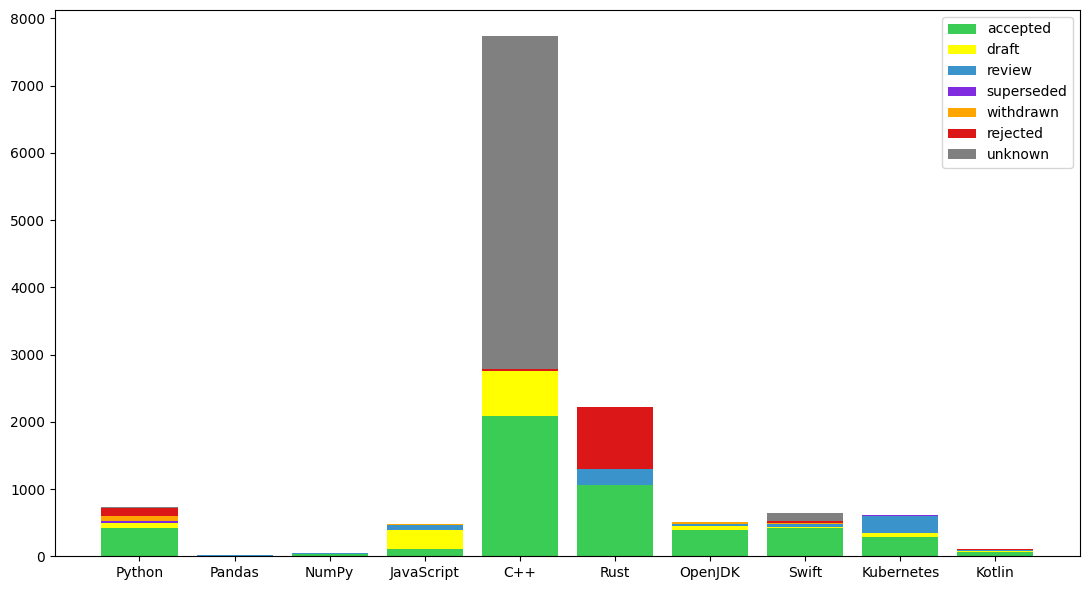

Status proportions (better view of small ones):


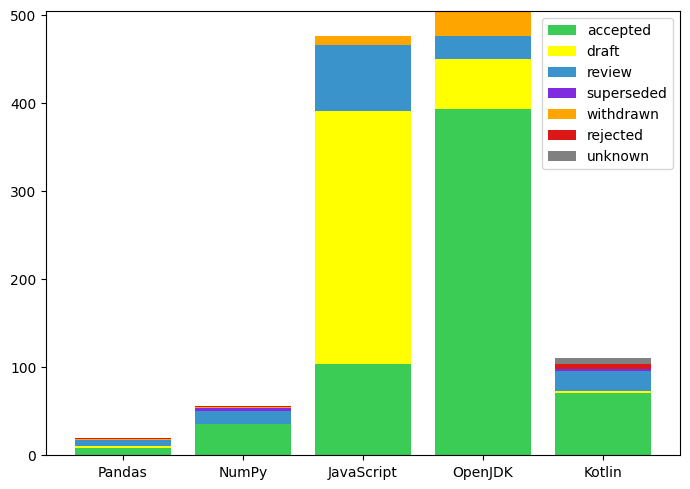

In [9]:
project_ids = projects.keys()

print('Current status proportions:')

_ = plt.figure(figsize=(11,6))
bar_sizes = bar_statuses_for_projects(project_ids)
_ = plt.legend([stat.value for stat in NormalisedStatus])
show_and_save('stat_bar')

print('Status proportions (better view of small ones):')

max_size = max(bar_sizes)
_ = plt.figure(figsize=(7,5))
_ = bar_statuses_for_projects([p_id for i, p_id in enumerate(project_ids) if bar_sizes[i] * 15 < max_size])
_ = plt.legend([stat.value for stat in NormalisedStatus])
show_and_save('stat_bar_small')

Next, I take a look at projects whose proposals have non-empty values in the `topic` field.

In [10]:
proposals_with_topics = list(session.scalars(select(Proposal)
  .where(Proposal.topic.is_not(None))
  .where(Proposal.topic.is_not(''))
  ))
projects_with_topics = list({p.project_id for p in proposals_with_topics})
print('IDs of projects with explicit proposal topics:', projects_with_topics)

IDs of projects with explicit proposal topics: [8, 9, 0]


In [11]:
def proposal_topics(prop: Proposal) -> set[str]:
  return set() if prop.topic is None else {top.lower().replace('-', '') for top in re.split(r', | / ', prop.topic)}

Topic distribution:


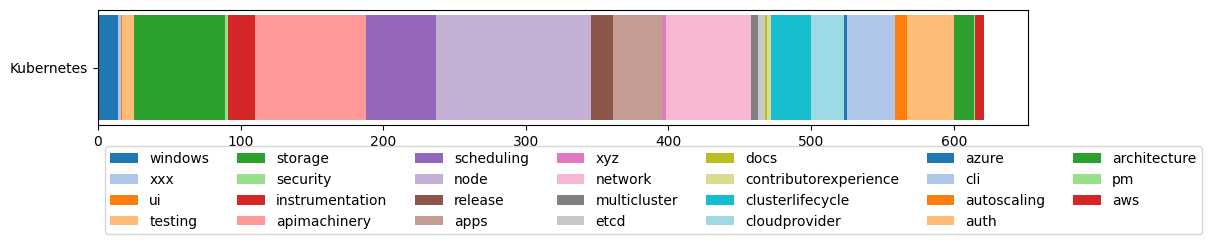

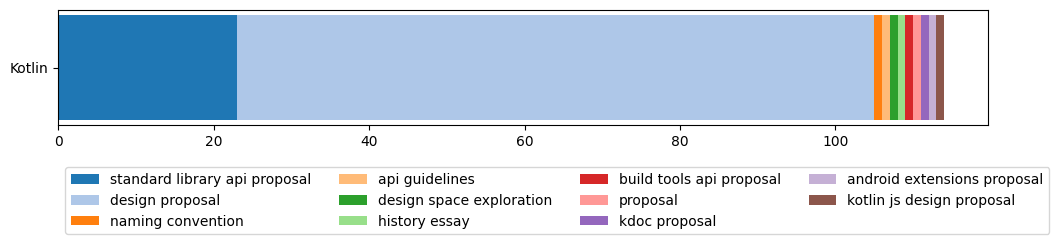

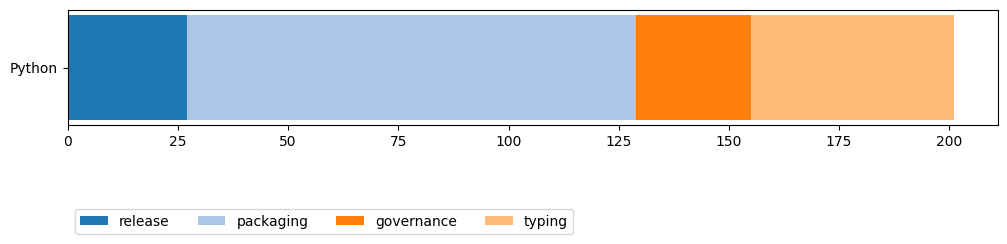

In [12]:
print('Topic distribution:')
for proj_id in projects_with_topics:
  topic_counts = Counter[str]()
  for prop in proposals_with_topics:
    if prop.project_id == proj_id:
      assert prop.topic, f'Fetched proposal with no topic ({proj_id}, {prop.proposal_id})'
      for topic in proposal_topics(prop):
        topic_counts[topic] += 1
  plt.figure(figsize=(12, 1.5))
  offset = 0
  color_id = 0
  for topic, count in topic_counts.items():
    _ = plt.barh([projects[proj_id].project_name], [count], height=0.1, left=offset,
      label=topic, color=plt.get_cmap('tab20')(color_id % 20))
    offset += count
    color_id += 1
  _ = plt.legend(loc='lower left', bbox_to_anchor=(0, -1), ncol={0:4, 8:7, 9:4}[proj_id])
  show_and_save(f'topic_distr_{projects[proj_id].project_name}', tight_layout=False)

## Manual Reading

Picking the most popular proposals in each project, for me to manually read through and discover topics:

In [13]:
from sqlalchemy import func, text

num_to_take = 5

print('By number of comments:')
for proj_id, project in projects.items():
  # raw query because orm is painfully slow
  most_comments = session.execute(text('''select p.proposal_id from Proposal p join Comment c
    on p.project_id == c.project_id and p.proposal_id == c.proposal_id
    where p.project_id == :pid
    group by p.proposal_id
    order by count(c.comment_id) desc, p.proposal_id desc
    limit :lim'''), params={'pid': proj_id, 'lim': num_to_take})
  # most_comments = session.scalars(select(Proposal.proposal_id)
  #   .join(Comment, onclause=Proposal.project_id.is_(Comment.project_id) & Proposal.proposal_id.is_(Comment.proposal_id))
  #   .where(Proposal.project_id.is_(project.project_id))
  #   .group_by(Proposal.proposal_id)
  #   .order_by(func.count(Comment.comment_id).desc())
  #   .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {[c[0] for c in most_comments]}')

print('By number of revisions:')
for proj_id, project in projects.items():
  most_comments = session.scalars(select(ProposalRevision.proposal_id)
    .where(ProposalRevision.project_id.is_(proj_id))
    .where(ProposalRevision.proposal_id.not_in(useless_proposals.get(proj_id, set())))
    .group_by(ProposalRevision.proposal_id)
    .order_by(func.count(ProposalRevision.revision_index).desc())
    .order_by(ProposalRevision.proposal_id.desc())
    .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {list(most_comments)}')

By number of comments:
PEP: ['8', '572', '517', '318', '426']
PDEP: []
NEP: ['14', '18', '20', '17', '41']
tc39: ['ShadowRealm', 'Decimal', 'Updates to Tail Calls to include an explicit syntactic opt-in', 'Record & Tuple', 'Import Attributes']
ISO C++: []
RFC: ['3946', '3892', '3855', '3834', '3830']
JEP: ['478', '491', '411', '450', '509']
Evolution: ['SE-0279', 'SE-0453', 'SE-0258', 'SE-0483', 'SE-0354']
KEP: ['4381', '3063', '4671', '3488', '127']
KEEP: ['0367', '0259', '0427', '0441', '0075']
By number of revisions:
PEP: ['11', '101', '1', '596', '619']
PDEP: ['1-1', '6-1', '10-1', '14-1', '12-1']
NEP: ['50', '35', '29', '18', '0']
tc39: ['Array.fromAsync', 'BigInt Math', 'Call-this operator', 'Bind-this operator', 'Unified class features']
ISO C++: ['P0447', 'P0876', 'P1018', 'P0260', 'P1928']
RFC: ['3537', '3923', '2873', '3389', '3503']
JEP: ['8377081', '401', '358', '430', '455']
Evolution: ['SE-0006', 'SE-0304', 'SE-0282', 'SE-0107', 'SE-0311']
KEP: ['1287', '3488', '4603', '1

Below are the manually identified topics from the proposals above:

In [14]:
sep_topics = {
  0: {
    '8': {'code style', 'advice'},
    '572': {'syntax'},
    '517': {'packaging'},
    '318': {'syntax', 'api structure'},
    '426': {'packaging'},
    '11': {'internal', 'compatibility'},
    '101': {'advice'},
    '1': {'meta'},
    '596': {'versioning', 'plan'},
    '619': {'versioning', 'plan'},
  },
  1: {
    '1-1': {'meta'},
    '6-1': {'typing'},
    '10-1': {'internal', 'typing', 'dev experience'},
    '14-1': {'typing'},
    '12-1': {'typing', 'api structure'},
  },
  2: {
    '14': {'deprecation'},
    '18': {'internal'},
    '20': {'syntax'},
    '17': {'api structure'},
    '41': {'typing', 'syntax'},
    '50': {'typing', 'dev experience'},
    '35': {'api structure', 'internal'},
    '29': {'versioning'},
    '0': {'meta'},
  },
  3: {
    'ShadowRealm': {'api structure'},
    'Updates to Tail Calls to include an explicit syntactic opt-in': {'syntax'},
    'Record & Tuple': {'syntax', 'typing'},
    'Import Attributes': {'syntax'},
    'Temporal': {'api structure'},
    'Array.fromAsync': {'api structure'},
    'BigInt Math': {'api structure'},
    'Call-this operator': {'syntax'},
    'Bind-this operator': {'syntax'},
    'Pattern Matching': {'syntax'},
  },
  5: {
    # '0078': {'dev experience'},
    # '0148': {'syntax'},
    # '0219': {'api structure', 'concurrency'},
    # '0235': {'api structure'},
    # '0439': {'api structure'},
    '3946': set[str](),
    '3892': {'api structure'},
    '3855': {'dev experience'},
    '3834': {'syntax'},
    '3830': {'syntax'},
    '3537': {'versioning', 'packaging'},
    '3923': {'packaging'},
    '2873': {'syntax'},
    '3389': {'syntax', 'packaging'},
    '3503': {'packaging'},
    # '3502': {'packaging'},
  },
  6: {
    '478': {'security', 'api structure'},
    '491': {'concurrency', 'performance'},
    '411': {'deprecation', 'security'},
    # '331': {'performance', 'api structure', 'memory'},
    # '472': {'dev experience'},
    '450': {'performance', 'memory'},
    '509': {'profiling'},
    # '537': {'api structure'},
    # '223': {'versioning', 'dev experience', 'api structure'},
    # '8380294': {'api structure', 'internal', 'performance'},
    # '522': {'performance', 'concurrency'},
    # '533': {'concurrency', 'api structure'},
    # '506': {'api structure', 'performance'},
    # '454': {'memory', 'api structure'},
    # '352': {'syntax'},
    '8377081': {'security', 'api structure'},
    '401': {'internal', 'syntax'},
    '358': {'dev experience'},
    '430': {'syntax'},
    '455': {'syntax', 'typing'},
  },
  7: {
    'SE-0279': {'syntax'},
    'SE-0453': {'typing', 'api structure'},
    'SE-0258': {'syntax'},
    'SE-0483': {'typing', 'syntax'},
    'SE-0354': {'syntax'},
    # 'SE-0492': {'syntax'},
    'SE-0006': set[str](),
    'SE-0304': {'concurrency'},
    'SE-0282': {'concurrency', 'memory'},
    'SE-0107': {'memory', 'api structure'},
    'SE-0311': {'concurrency'},
  },
  9: {
    '0367': {'syntax'},
    '0259': {'syntax'},
    '0427': {'syntax', 'typing'},
    '0441': {'syntax', 'typing', 'dev experience'},
    '0075': {'syntax'},
    '0455': {'syntax'},
    '0452': {'internal', 'syntax'},
    '0430': {'syntax'},
    '0104': {'syntax', 'internal'},
  },
}

In [15]:
found_topic_counts = Counter[str]()
for proj_topics in sep_topics.values():
  for prop_topics in proj_topics.values():
    for prop_topic in prop_topics:
      found_topic_counts[prop_topic] += 1
print('Topics found at least twice:', [t for t, cnt in found_topic_counts.items() if cnt >= 2])

Topics found at least twice: ['advice', 'syntax', 'packaging', 'api structure', 'internal', 'meta', 'plan', 'versioning', 'typing', 'dev experience', 'deprecation', 'security', 'performance', 'concurrency', 'memory']


Explanations of each topic:

In [16]:
topic_explanations: dict[str, str] = {}

In [17]:
topic_explanations.update({
  'advice': 'Informational advice, code style guidelines',
  'syntax': 'Built-in syntax of language, keywords, expressions',
  'api structure': 'Pre-written code, libraries, function signatures',
  'packaging': 'Package manager, third-party packages, build system',
  'internal': 'Inner code mechanisms, compiler',
  # 'meta': 'About software enhancement proposals themselves, governance, for {project_name}, {sep_name}',
  'versioning': 'Version control, version naming scheme',
  'plan': 'Plans, schedules for maintainers',
  'typing': 'Type system of programming language or library, data types, classes',
  'dev experience': 'Features for the convenience of developers, ease of use, permissions, logging, exceptions, error messages',
  'performance': 'Time efficiency, memory efficiency, power consumption',
  'deprecation': 'Deprecation of features, marking for removal',
  'memory': 'Low-level memory operation, garbage collection',
  'security': 'Cybersecurity, security patches, encryption, hashing, key generation',
  'concurrency': 'Parallelism, threads, multithreading, asynchronous, concurrency',
})

Some SEPs are meta (about the process itself, about SEPs themselves)

In [18]:
meta_seps = {
  1: {'1-1'},
  5: {'0002', '0006', '0031', '0032', '0082', '0140', '0190', '0232', '0506', '0531', '0815', '1224', '1329', '1569', '1607', '1636',
    '1728', '1810', '1981', '2044', '2047', '2059', '2075', '2299', '2333', '2432', '2561', '3339'},
}

def is_meta_sep(proj_id: int, prop_id: str) -> bool:
  if(proj_id in {0, 2, 6}):
    prop = get_proposal(proj_id, prop_id)
    return prop is not None and prop.proposal_type == 'Process'
  return prop_id in meta_seps.get(proj_id, set())

## Clustering

Step 1 - Fetching titles and contents of SEPs. Only considering the most recent ones

In [19]:
"""
Gets the latest revision of a proposal
None if a proposal has no revisions
"""
def proposal_latest_revision(project_id: int, proposal_id: str) -> ProposalRevision | None:
  return session.scalar(select(ProposalRevision)
    .where(ProposalRevision.project_id.is_(project_id))
    .where(ProposalRevision.proposal_id.is_(proposal_id))
    .order_by(ProposalRevision.created_at.desc())
    .limit(1))

def revision_content(rev: ProposalRevision) -> str:
  return rev.content

def revision_title(rev: ProposalRevision) -> str:
  return rev.title

"""
Gets the latest revision of each given proposal, if any
"""
def proposals_latest_revisions(props: Iterable[tuple[int, str]]) -> list[ProposalRevision]:
  revs = [proposal_latest_revision(proj_id, prop_id) for proj_id, prop_id in props]
  return [rev for rev in revs if rev is not None]

"""
Gets the latest revision of each proposal in the given project
"""
def project_latest_revisions(proj_id: int) -> list[ProposalRevision]:
  return proposals_latest_revisions([(proj_id, prop_id) for prop_id in project_proposals(proj_id)])

Step 2 - Sanitization strategies for each project

In [20]:
from bs4 import BeautifulSoup

def sanitize_markdown(content: str) -> str:
  return re.sub(r'<!--(?:(?!-->)[\s\S])+-->', '', # remove comments
    re.sub(r'```(?:(?!```)[\s\S])+```', '', # remove code blocks
    re.sub(r'\n\|[^\n]*', '', content))) # remove tables (lines starting with |)

useless_tags = {'meta', 'script', 'title', 'pre', 'style'}
def sanitize_html(content: str) -> str:
  doc = BeautifulSoup(content, features='html.parser')
  for tag in useless_tags:
    for elem in doc(tag):
      _ = elem.extract()
  return doc.get_text()

def sanitize_pep(content: str) -> str:
  return re.sub(r'^[^A-Za-z0-9\n]+\n|\n[^A-Za-z0-9\n]+\n|\n[^A-Za-z0-9\n]+$', '\n', # remove lines with no alphanumeric characters
    re.sub(r'References\n[\s\S]*$|Copyright\n[\s\S]*$', '', content)) # remove everything starting from references or copyright section (usually nothing important)

def sanitize_pdep(content: str) -> str: # these are markdown
  return sanitize_markdown(content)

def sanitize_nep(content: str) -> str: # similar to pep
  return re.sub(r'^[^\n]*\n', '', # remove first line remaining, which is the title
    re.sub(r'^\.\.[^.\n]*\n', '',
    re.sub(r'\n\.\.[^.\n]*\n', '\n', # remove lines that start with ..
    sanitize_pep(content))))

def sanitize_tc39(content: str) -> str:
  return (sanitize_html if content.strip().startswith('<') else sanitize_markdown)(content)

def sanitize_rust(content: str) -> str:
  return re.sub(r'^[\s\S]*# Summary', '', # remove all before summary (metadata)
    sanitize_markdown(content))

def sanitize_jep(content: str) -> str:
  return re.sub(r'<code>(?:(?!</code>)[\s\S])+</code>', '', content) # remove code blocks

def sanitize_swift(content: str) -> str:
  return re.sub(r'^[\s\S]*# Introduction|^[\s\S]*# Summary', '', # remove all before introduction/summary (metadata)
    sanitize_markdown(content))

def sanitize_keep(content: str) -> str:
  return sanitize_markdown(content)

content_sanitizer = {
  0: sanitize_pep,
  1: sanitize_pdep,
  2: sanitize_nep,
  3: sanitize_tc39,
  5: sanitize_rust,
  6: sanitize_jep,
  7: sanitize_swift,
  9: sanitize_keep,
}

"""
Cleans up the content of a proposal
Picks strategy based on which project it comes from
"""
def sanitize_content(project_id: int, content: str) -> str:
  sanitize = content_sanitizer.get(project_id, identity)
  return re.sub(r'[^A-Za-z0-9 .?!,]', ' ', # remove characters except alphanumeric, space and sentence separators
    re.sub(r'https?://\S+', '', # remove URLs
    sanitize(content)))

def sanitize_title_rust(title: str) -> str:
  return re.sub(r'^[Rr][Ff][Cc]:', '', title)

def sanitize_title_jep(title: str) -> str:
  return re.sub(r'^JEP\s+\S*\s*[:-]|^JEP:|^JEP XXX|^Draft\s+JEP:', '', title)

title_sanitizer = {
  5: sanitize_title_rust,
  6: sanitize_title_jep,
}

"""
Cleans up the title of a proposal
Picks strategy based on which project it comes from
"""
def sanitize_title(project_id: int, title: str) -> str:
  sanitize = title_sanitizer.get(project_id, identity)
  return re.sub(r'[^A-Za-z0-9 ]', ' ', # remove non-alphanum chars
    sanitize(title)).strip()

Step 3 - Splitting text into manageable sentence tokens. Titles remain in one piece

In [21]:
from nltk.tokenize import sent_tokenize

"""
Split content into sentences
Can specify how many sentences to keep (int), or ratio (float between 0-1), starting from the first
"""
def tokenize_content(keep_count_or_ratio: int | float | None = None) -> Callable[[str], list[str]]:
  def ratio_tok(clean_content: str) -> list[str]:
    sentences = sent_tokenize(clean_content)
    l = len(sentences)
    n = l if keep_count_or_ratio is None else max(1, min(l,
      keep_count_or_ratio if isinstance(keep_count_or_ratio, int) else int(l * keep_count_or_ratio)))
    return sentences[:n]
  return ratio_tok

"""
Title is one sentence
"""
def tokenize_title(clean_title: str) -> list[str]:
  return [clean_title]

Step 4 - Embedding sentences into vectors using pre-trained models

In [22]:
from sentence_transformers import SentenceTransformer

Embedding = np.ndarray[tuple[int], np.dtype[np.float64]]

"""
Generate dense embedding, per sentence, using SBERT model
Specify save file to cache the result
Returns ndarray of sizes (n_sentences, n_dimensions)
"""
def generate_embedding(sentences: str | list[str], embedder: SentenceTransformer,
    save_file: str | None = None) -> np.ndarray[tuple[int, int], np.dtype[np.float64]]:
  embedding = None
  while embedding is None:
    embedding = embedder.encode(sentences, normalize_embeddings=True, convert_to_numpy=True, output_value='sentence_embedding')
    if np.any(np.isnan(embedding)):
      embedding = None
  if save_file is not None:
    np.save(open(save_file, 'wb'), embedding)
  return embedding

# Whether or not to cache embedding results
use_numpy_save = True

"""
Get embedding for a given proposal, with given sentences of text
Aggregates sentence embeddings by taking the mean
Can fetch embeddings from cache file or save them to it
Returns ndarray of size (n_dimensions,)
"""
def get_proposal_embedding(sentences: str | list[str], embedder: SentenceTransformer,
    project_id: int, proposal_id: str,
    embedder_name: str, strategy: str) -> Embedding:
  assert len(sentences) > 0, f'Empty content provided for embedding ({project_id}, {proposal_id}, {strategy})'
  sent_embeds = None
  if use_numpy_save:
    save_dir = f'cache/embeddings/{project_id}'
    os.makedirs(save_dir, exist_ok=True)
    file_name = f'{save_dir}/{proposal_id.replace('/', '')}-{embedder_name}-{strategy}.npy'
    try:
      sent_embeds = np.load(open(file_name, 'rb'))
    except:
      sent_embeds = generate_embedding(sentences, embedder, save_file=file_name)
  else:
    sent_embeds = generate_embedding(sentences, embedder)
  return np.mean(sent_embeds, axis=0)

Step 5 - Clustering the embeddings

In [23]:
from sklearn.base import ClusterMixin
from sklearn.cluster import KMeans, AgglomerativeClustering

def kmeans(n: int, seed: int) -> ClusterMixin:
  return KMeans(n_clusters=n, random_state=seed)

def agg_clusterer(n: int, _: int) -> ClusterMixin:
  return AgglomerativeClustering(n_clusters=n)

In [24]:
ClusterLabel = int

"""
Clusters embeddings using given clusterer strategy and target number of clusters
Returns label list of length n_embeds
"""
def cluster_embeds(embeds: Iterable[Embedding],
    clusterer: Callable[[int, int], ClusterMixin],
    num_clusters: int) -> Iterable[ClusterLabel]:
  return clusterer(num_clusters, random_seed).fit_predict(embeds)

In [25]:
# for each name of strategy: text extractor, sanitizer, tokenizer
embedding_strats = {
  'content': (revision_content, sanitize_content, tokenize_content()),
  'half_content': (revision_content, sanitize_content, tokenize_content(0.5)),
  '20_percent_content': (revision_content, sanitize_content, tokenize_content(0.2)),
  'first_20_sentences': (revision_content, sanitize_content, tokenize_content(20)),
  'title': (revision_title, sanitize_title, tokenize_title),
}

In [26]:
"""
Combiner function: sanitizes, tokenizes, embeds, clusters
Takes as input a list of project_id, proposal_id and associated proposal revision
Returns for each an embedding and a label, as parallel lists
"""
def cluster_revisions(revisions: Iterable[tuple[int, str, ProposalRevision]],
    embedder: SentenceTransformer,
    embedder_name: str,
    embedding_strat: str,
    clusterer: Callable[[int, int], ClusterMixin],
    num_clusters: int) -> tuple[list[Embedding], Iterable[ClusterLabel]]:
  get_text, sanitize, tokenize = embedding_strats[embedding_strat]
  token_lists = [(proj_id, prop_id, tokenize(sanitize(proj_id, get_text(rev))))
      for proj_id, prop_id, rev in revisions]
  embeds = [get_proposal_embedding(tokens, embedder, proj_id, prop_id, embedder_name, embedding_strat)
    for proj_id, prop_id, tokens in token_lists]
  for i, e in enumerate(embeds):
    if np.any(np.isnan(e)): print(token_lists[i][1], embedding_strat, e)
  return embeds, cluster_embeds(embeds, clusterer, num_clusters)

In [27]:
from matplotlib.axes._axes import Axes

def plot_clust_performances(proposals: Iterable[tuple[int, str]],
    embedder: SentenceTransformer,
    embedder_name: str,
    clusterer: Callable[[int, int], ClusterMixin],
    clusterer_name: str,
    cluster_counts: list[int],
    performance_metric: Callable[[Iterable[Embedding], Iterable[ClusterLabel]], float],
    ax: Axes):
  _ = ax.set_title(f'{clusterer_name} clustering')
  for strat_name in embedding_strats:
    maybe_revisions = [(proj_id, prop_id, proposal_latest_revision(proj_id, prop_id))
      for proj_id, prop_id in proposals]
    revisions = [(proj_id, prop_id, rev) for proj_id, prop_id, rev in maybe_revisions if rev is not None]
    embeds_labels = [cluster_revisions(revisions, embedder, embedder_name, strat_name, clusterer, num_clusters) for num_clusters in cluster_counts]
    scores = [performance_metric(embeds, labels) for embeds, labels in embeds_labels]
    _ = ax.plot(cluster_counts, scores, label=strat_name)
  _ = ax.set_xticks(cluster_counts)
  _ = ax.set_ylim(bottom=0)
  _ = ax.set_xlabel('cluster #')
  _ = ax.set_ylabel('silhouette score')
  _ = ax.legend()

In [28]:
from sklearn.metrics import silhouette_score

def plot_clust_performance_on_project(project_id: int, embedder: SentenceTransformer, embedder_name: str):
  prop_ids = project_proposals(project_id)
  # prop_titles_contents = [proposal_latest_title_content(project_id, prop_id) for prop_id in prop_ids]
  # prop_ids_titles_contents = [(prop_ids[i], title_content[0], title_content[1])
  #   for i, title_content in enumerate(prop_titles_contents) if title_content is not None]
  # prop_ids_sentences = [(prop_id, [sanitize_title(project_id, title)], sent_tokenize(sanitize_content(project_id, content)))
  #   for prop_id, title, content in prop_ids_titles_contents]
  # title_embeds = [get_proposal_embedding(title, embedder, project_id, prop_id, embedder_name, 'title')
  #   for prop_id, title, _ in prop_ids_sentences]
  # content_embeds = [get_proposal_embedding(content, embedder, project_id, prop_id, embedder_name, 'content')
  #   for prop_id, _, content in prop_ids_sentences]
  # for i, e in enumerate(content_embeds):
  #   if np.any(np.isnan(e)): print(prop_ids_titles_contents[i][0], e)
  
  # cluster_counts = list(range(2, 15))
  # fig, (ax1, ax2) = plt.subplots(1, 2)
  # fig.set_figwidth(20)
  # _ = fig.suptitle(f'Clustering performance for embedding - {projects[project_id].project_name}')
  # plot_clust_performances(title_embeds, cluster_counts,
  #   f'Title-based', ax1)
  # plot_clust_performances(content_embeds, cluster_counts,
  #   f'Content-based', ax2)
  plt.rc('font', size=13)
  fig, (ax1, ax2) = plt.subplots(1, 2)
  _ = fig.set_size_inches(13, 5)
  _ = fig.suptitle(f'Clustering performance with {embedder_name} embedder - {projects[project_id].project_name}')
  cluster_counts = list(range(2, 15))
  plot_clust_performances([(project_id, prop_id) for prop_id in prop_ids],
    embedder, embedder_name, kmeans, 'k-means', cluster_counts, silhouette_score, ax1)
  plot_clust_performances([(project_id, prop_id) for prop_id in prop_ids],
    embedder, embedder_name, agg_clusterer, 'agglomerative', cluster_counts, silhouette_score, ax2)
  show_and_save(f'clust_{embedder_name}_{projects[project_id].project_name}')
  plt.rcdefaults()

I explore every project except C++ and JS, because of how different their paradigm is.

In [29]:
project_ids_to_explore = [proj_id for proj_id in projects if proj_id not in {3, 4}]

In [30]:
minilm_embedder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2', token=os.getenv('HF_TOKEN'))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

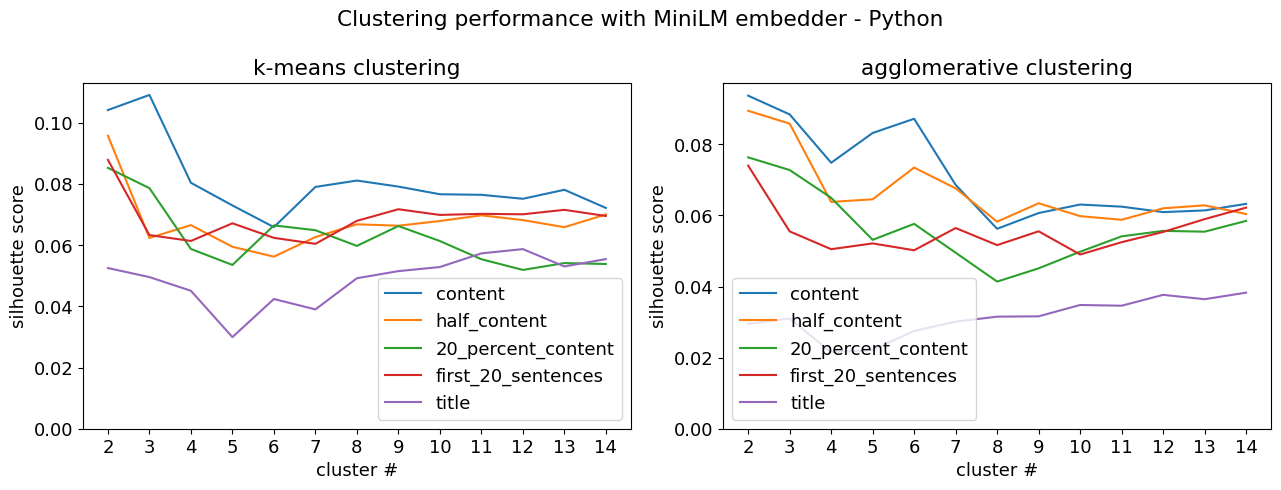

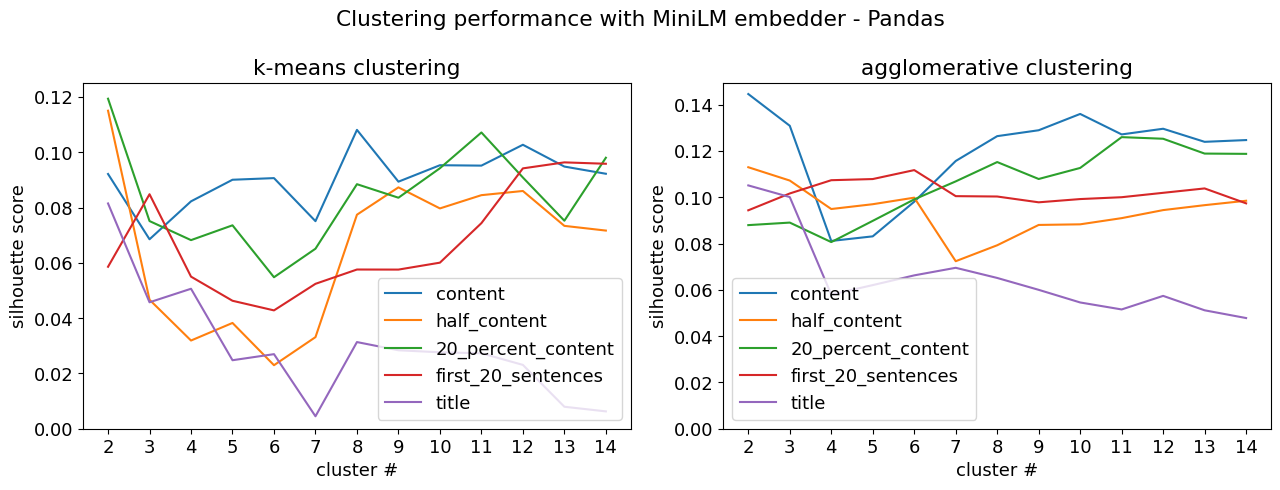

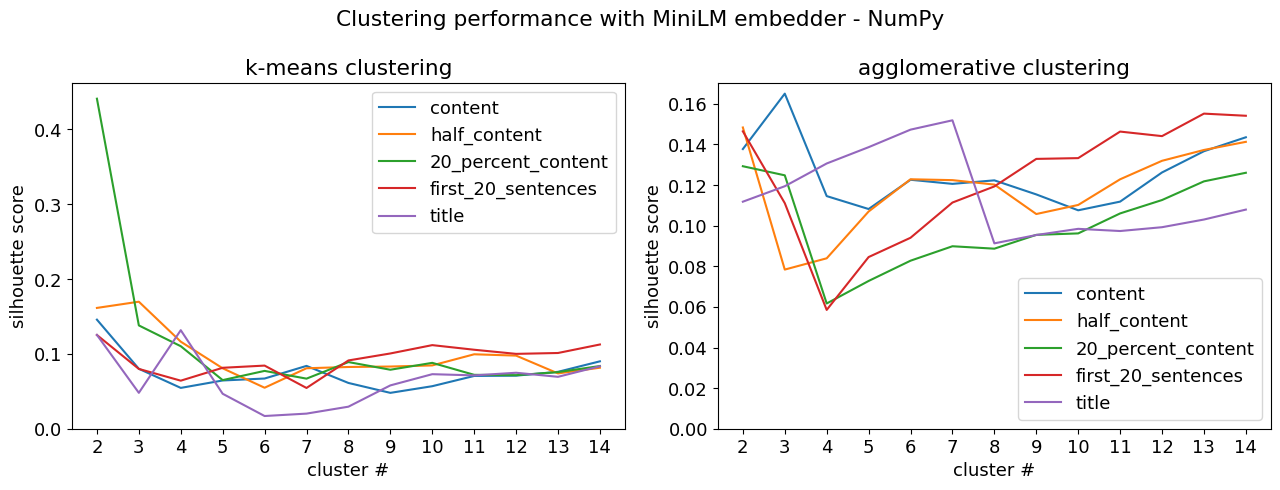

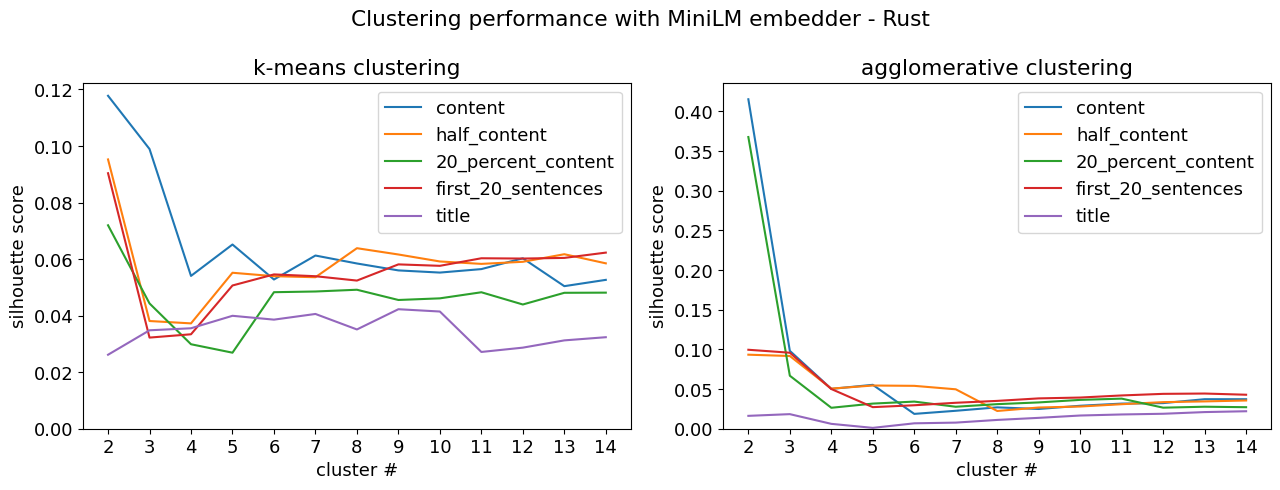

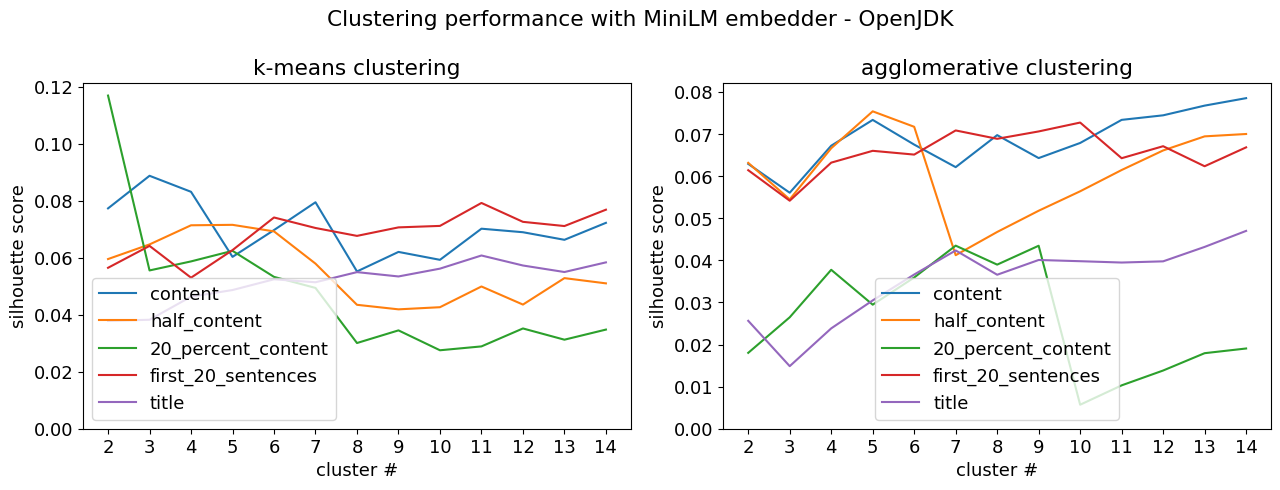

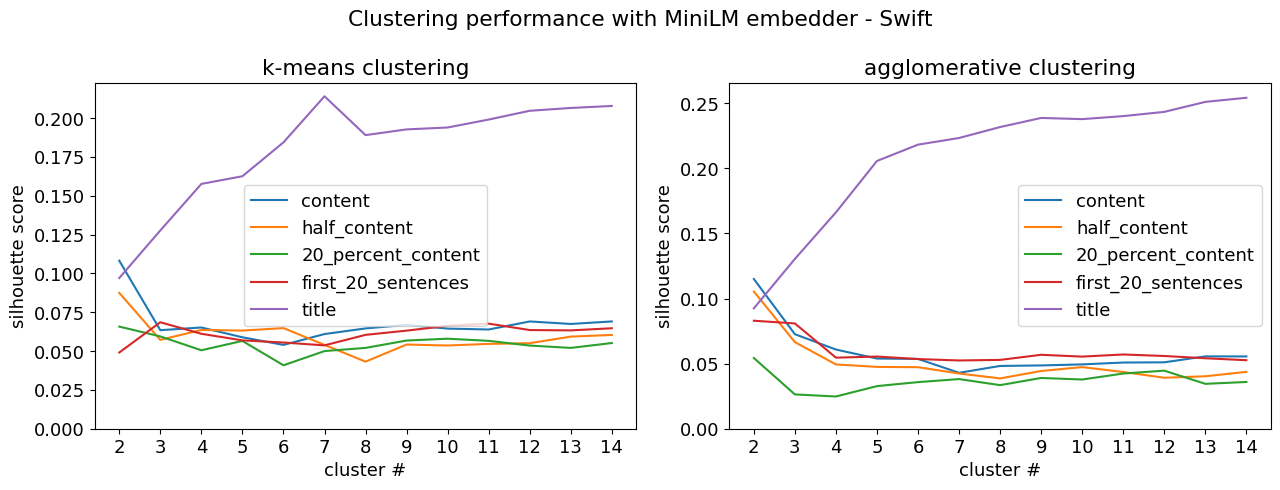

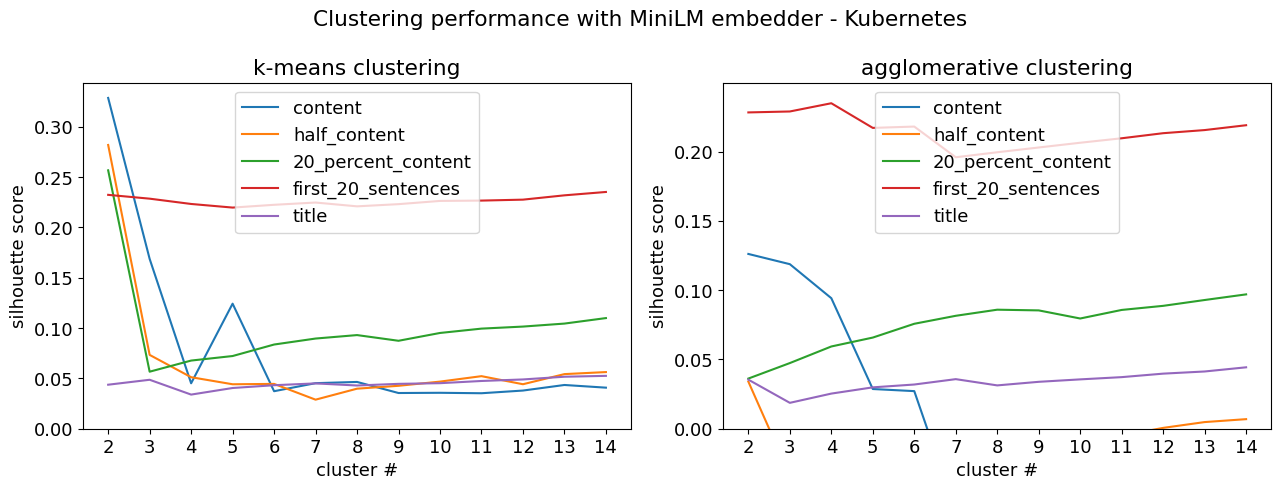

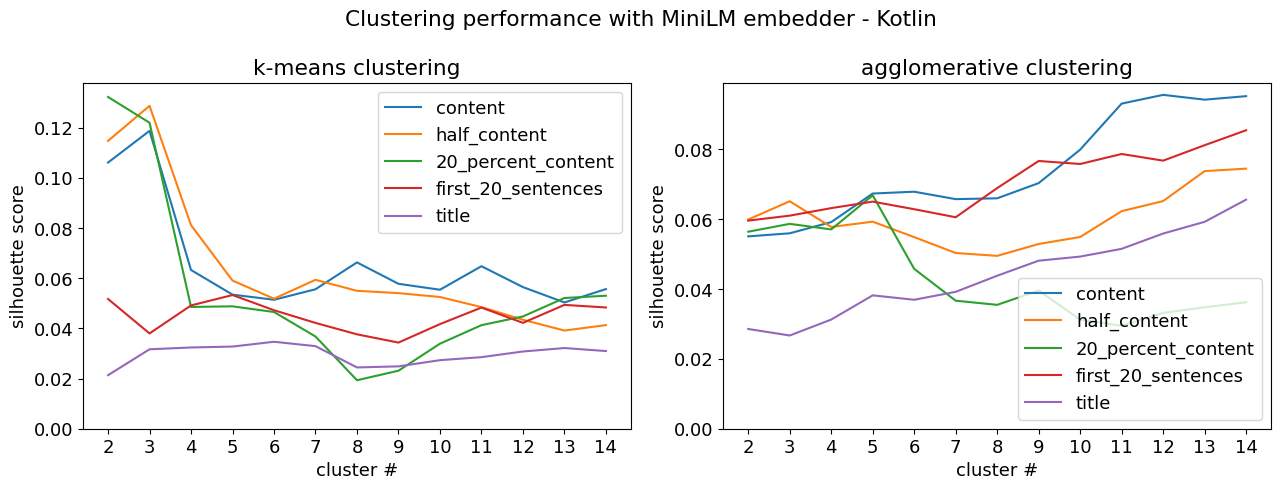

In [110]:
for proj_id in project_ids_to_explore:
  plot_clust_performance_on_project(proj_id, minilm_embedder, 'MiniLM')

In [31]:
mpnet_embedder = SentenceTransformer("all-mpnet-base-v2", token=os.getenv('HF_TOKEN'))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

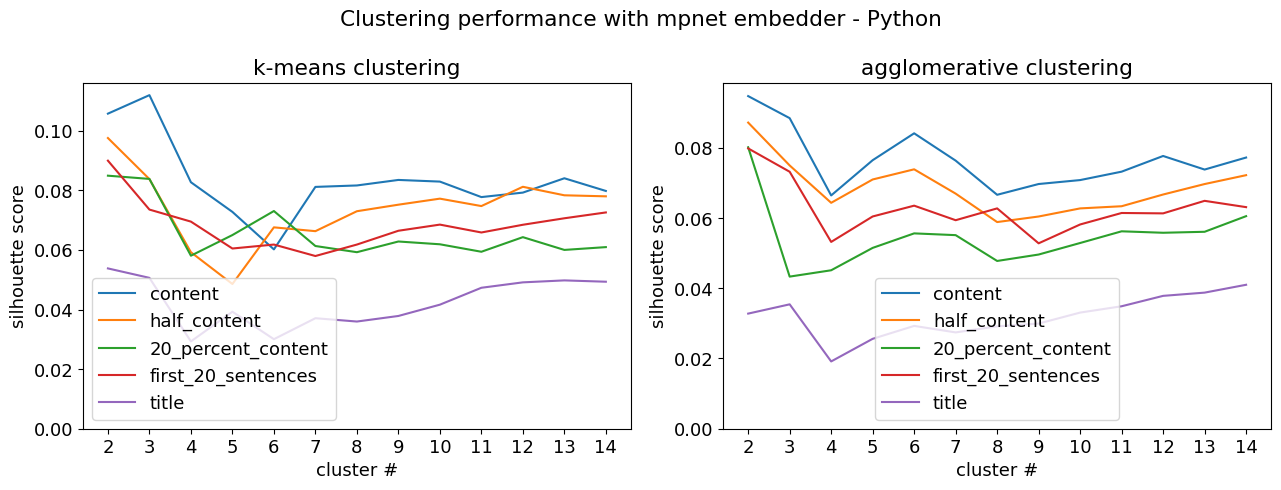

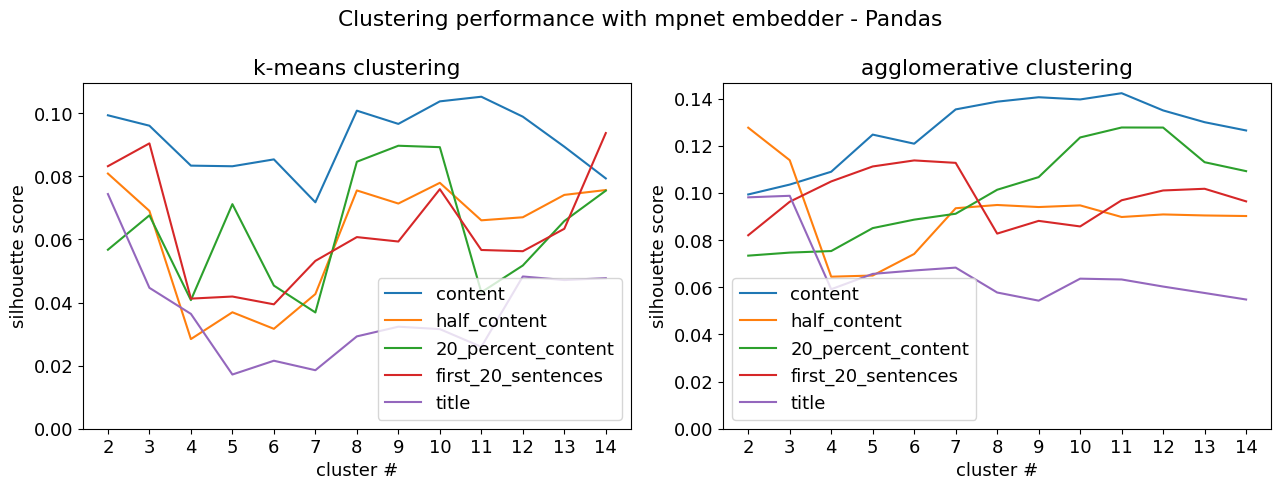

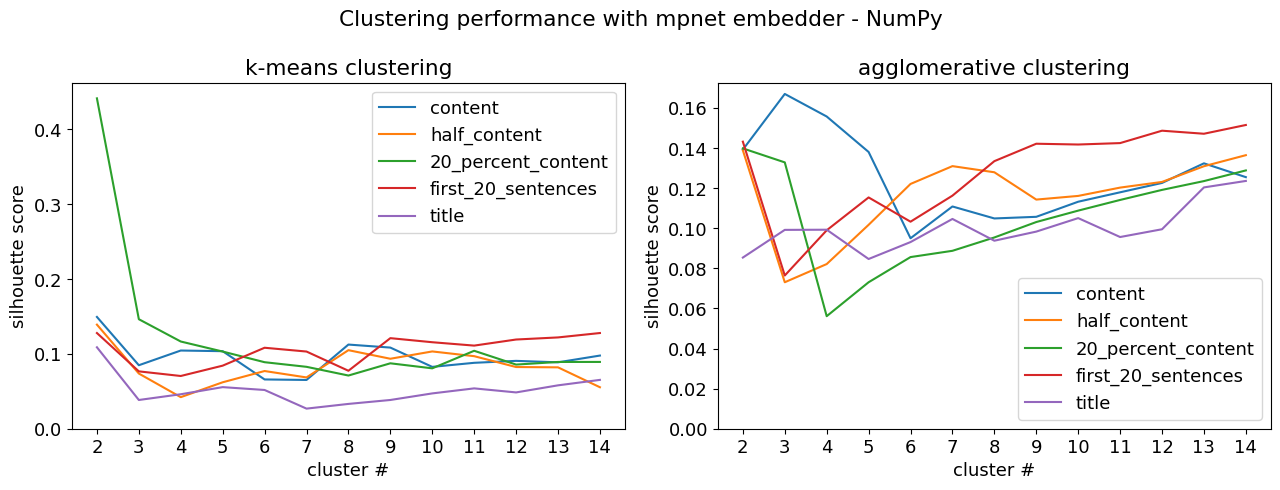

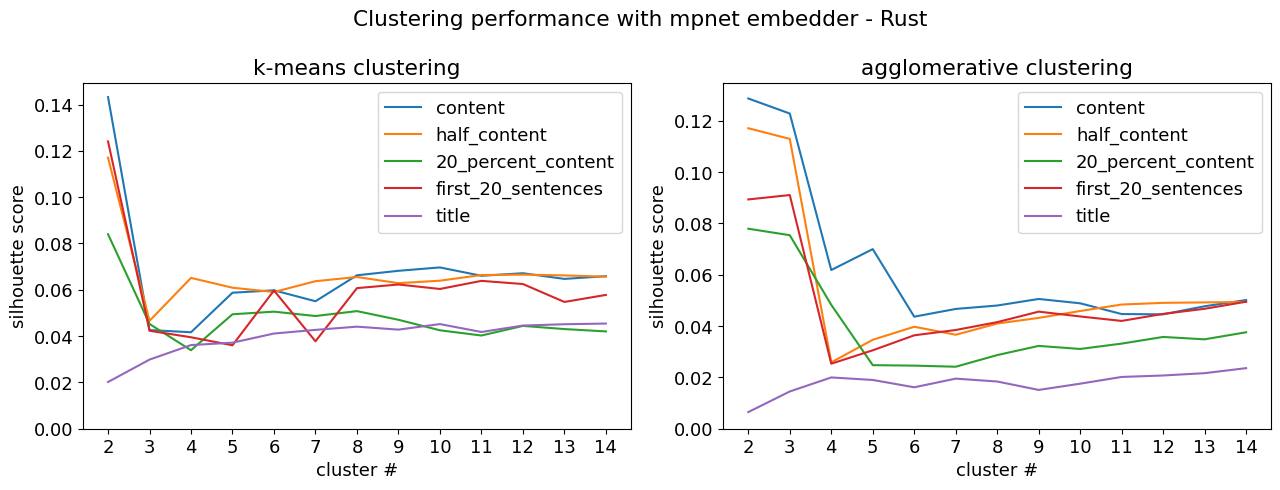

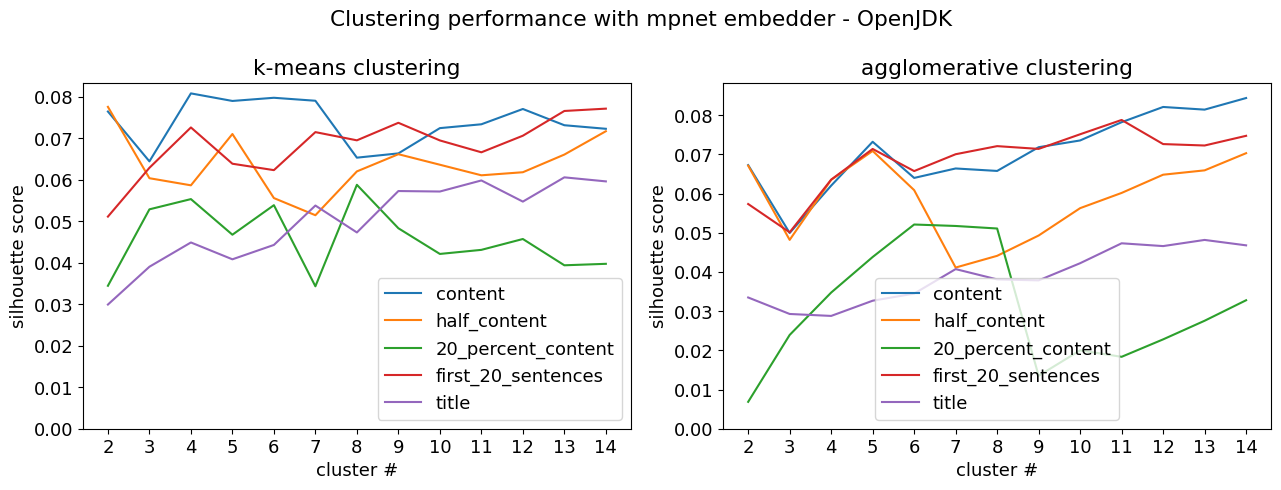

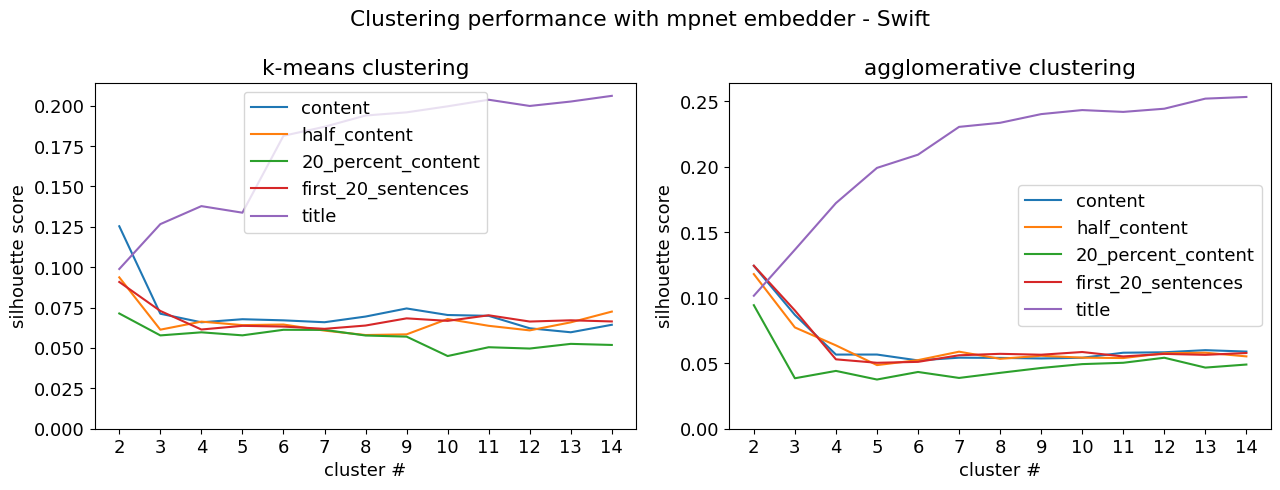

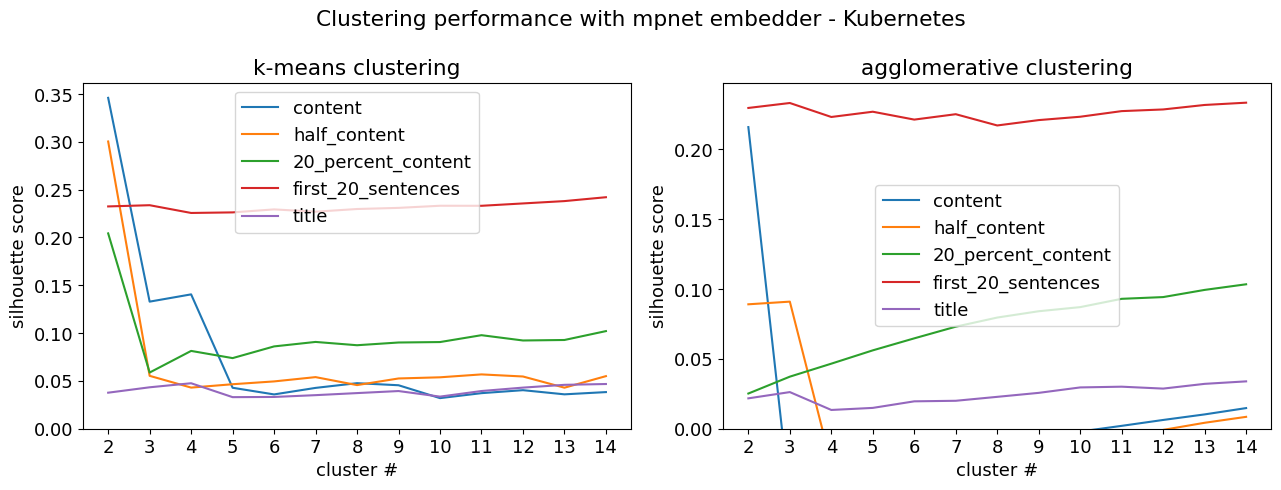

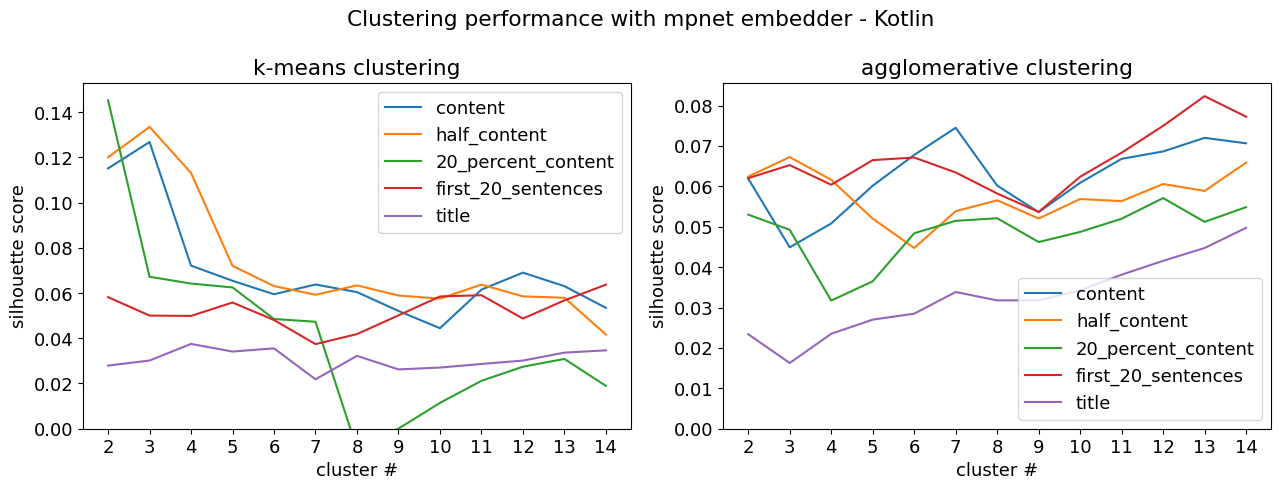

In [111]:
for proj_id in project_ids_to_explore:
  plot_clust_performance_on_project(proj_id, mpnet_embedder, 'mpnet')

In [32]:
def get_project_clusters(proj_id: int, clusterer: Callable[[int, int], ClusterMixin], num_clusters: int, embed_strat: str) \
    -> dict[int, list[tuple[str, Embedding]]]:
  props_to_check = project_proposals(proj_id)
  prop_revs_to_check_maybe = [(id, proposal_latest_revision(proj_id, id)) for id in props_to_check]
  prop_revs_to_check = [(proj_id, id, r) for id, r in prop_revs_to_check_maybe if r is not None]
  check_embeds, check_labels = cluster_revisions(prop_revs_to_check, minilm_embedder, 'MiniLM', embed_strat, clusterer, num_clusters)
  proposals_by_label = {l: list[tuple[str, Embedding]]() for l in range(num_clusters)}
  for i, l in enumerate(check_labels):
    proposals_by_label[l].append((prop_revs_to_check[i][1], check_embeds[i]))
  return proposals_by_label

In [33]:
proposals_by_label = get_project_clusters(2, kmeans, 2, 'content')
for l, props in proposals_by_label.items():
  print(l, [prop_id for prop_id, _ in props])

0 ['1', '10', '11', '12', '13', '15', '16', '17', '18', '2', '20', '21', '22', '24', '25', '26', '27', '3', '30', '31', '34', '35', '37', '38', '4', '40', '41', '42', '43', '45', '47', '49', '5', '50', '51', '55', '56', '7', '8', '9']
1 ['0', '14', '19', '23', '28', '29', '32', '36', '44', '46', '48', '52', '53', '54', '57', '6']


Trying agglomerative clustering on OpenJDK, with 11 clusters

In [34]:
proj_id_to_check = 6
clusterer_to_check = agg_clusterer
num_clusters_to_check = 11

props_to_check = project_proposals(proj_id_to_check)
prop_revs_to_check_maybe = [(id, proposal_latest_revision(proj_id_to_check, id)) for id in props_to_check]
prop_revs_to_check = [(proj_id_to_check, id, r) for id, r in prop_revs_to_check_maybe if r is not None]
check_embeds, check_labels = cluster_revisions(prop_revs_to_check, minilm_embedder, 'MiniLM', 'content', clusterer_to_check, num_clusters_to_check)
indices_by_label = {l: list[int]() for l in range(num_clusters_to_check)}
for i, l in enumerate(check_labels):
  indices_by_label[l].append(i)
for l, idxs in indices_by_label.items():
  print(l, [prop_revs_to_check[i][1] for i in idxs])

0 ['102', '103', '107', '109', '126', '132', '138', '139', '143', '145', '148', '151', '155', '160', '167', '169', '171', '176', '177', '180', '188', '191', '192', '193', '196', '199', '210', '230', '232', '233', '234', '235', '240', '241', '242', '243', '250', '254', '259', '266', '269', '276', '279', '280', '281', '284', '285', '295', '303', '306', '309', '310', '315', '317', '328', '331', '334', '341', '342', '348', '349', '350', '399', '410', '416', '421', '431', '435', '472', '483', '500', '502', '509', '514', '515', '518', '520', '526', '528', '531', '8132243', '8158765', '8179657', '8201462', '8208520', '8209964', '8221828', '8223220', '8248257', '8249196', '8260688', '8261007', '8261099', '8284453', '8297156', '8297236', '8335368', '8336232', '8350458', '8354416', '8357674', '8380294', '8381322']
1 ['101', '181', '186', '215', '216', '218', '274', '286', '300', '301', '302', '305', '323', '325', '326', '354', '355', '359', '360', '361', '368', '371', '375', '378', '384', '394',

In [35]:
jep_label_meanings_and_examples = {
  0: [('other', set[str]())],
  1: [('syntax', {'186', '323', '368', '394', '465'}), ('typing', {'215', '218', '286', '8204937', '8258000'})],
  2: [('memory', {'144', '163', '189', '304', '534'})],
  3: [('security', {'116', '121', '130', '166', '246'})],
  4: [('meta', {'1', '11', '12', '3'}), ('other', set[str]())],
  5: [('concurrency', {'270', '376', '425', '428', '506'})],
  6: [('network', {'183', '321', '337', '418', '517'}), ('graphics', {'205', '209', '239', '263', '265'})],
  7: [('platform support', {'175', '237', '362', '391', '422'})],
  8: [('vector api', {'338', '414', '460', '508', '537'})], # all revisions of the same proposal
  9: [('text encoding', {'111', '226', '267', '327', '8371379'})],
  10: [('dev experience', {'118', '136', '140', '158', '245'})],
}

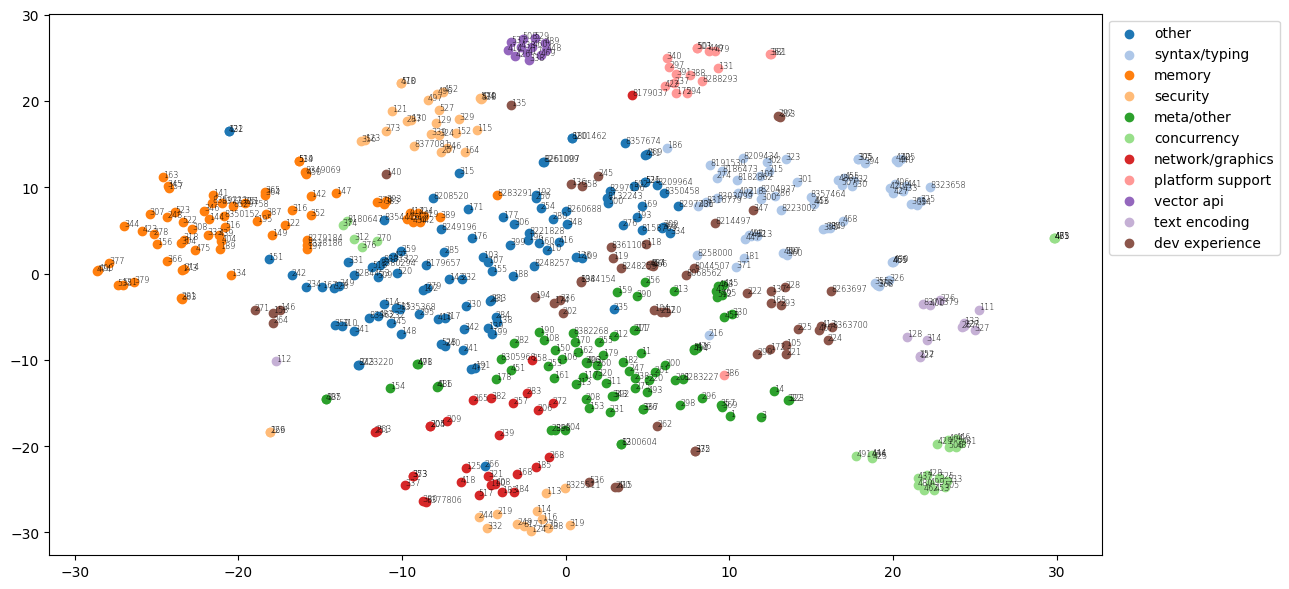

In [36]:
from sklearn.manifold import TSNE

umap_2d = TSNE(n_components=2, random_state=random_seed)
check_embeds_2d = umap_2d.fit_transform(np.array(check_embeds))
_ = plt.figure(figsize=(13,6))
for lab_id, idxs in indices_by_label.items():
  label_embeds = np.array([check_embeds_2d[i] for i in idxs])
  _ = plt.scatter(label_embeds[:,0], label_embeds[:,1],
    label='/'.join([meaning for meaning, _ in jep_label_meanings_and_examples[lab_id]]),
    color=plt.get_cmap('tab20')(lab_id))
  for idx in idxs:
    _ = plt.annotate(prop_revs_to_check[idx][1], (check_embeds_2d[idx][0], check_embeds_2d[idx][1]), size='xx-small', weight='light')
  _ = plt.legend(bbox_to_anchor=(1, 1))
show_and_save('scatt_jep')

In [37]:
topic_explanations.update({
  'network': 'Network protocols, IP, HTTP',
  'platform support': 'Compatibility and porting to hardware or operating system',
})

In [38]:
all_topics = list(topic_explanations.keys())
print('Total number of topics:', len(all_topics))

Total number of topics: 16


## Classification

In [39]:
from torch import Tensor

"""
Computes similarities between proposals and topics
Returns float matrix of shape (n_proposals, n_topics)
"""
def similarities_with_topics(prop_revs: Iterable[ProposalRevision], topics: Iterable[str],
    embedder: SentenceTransformer, embedder_name: str, embed_strat: str) -> Tensor:
  explanations = [topic_explanations[topic] for topic in topics]
  topic_embeds = np.array([embedder.encode(expl, normalize_embeddings=True, convert_to_numpy=True, output_value='sentence_embedding')
    for expl in explanations], dtype=np.float32)

  get_text, sanitize, tokenize = embedding_strats[embed_strat]
  embs = np.array([get_proposal_embedding(
      tokenize(sanitize(rev.project_id, get_text(rev))),
      embedder, rev.project_id, rev.proposal_id, embedder_name, embed_strat)
    for rev in prop_revs], dtype=np.float32)
  return embedder.similarity(embs, topic_embeds)

Using the SEP examples for which I previously identified topics manually, I optimize the similarity threshold:

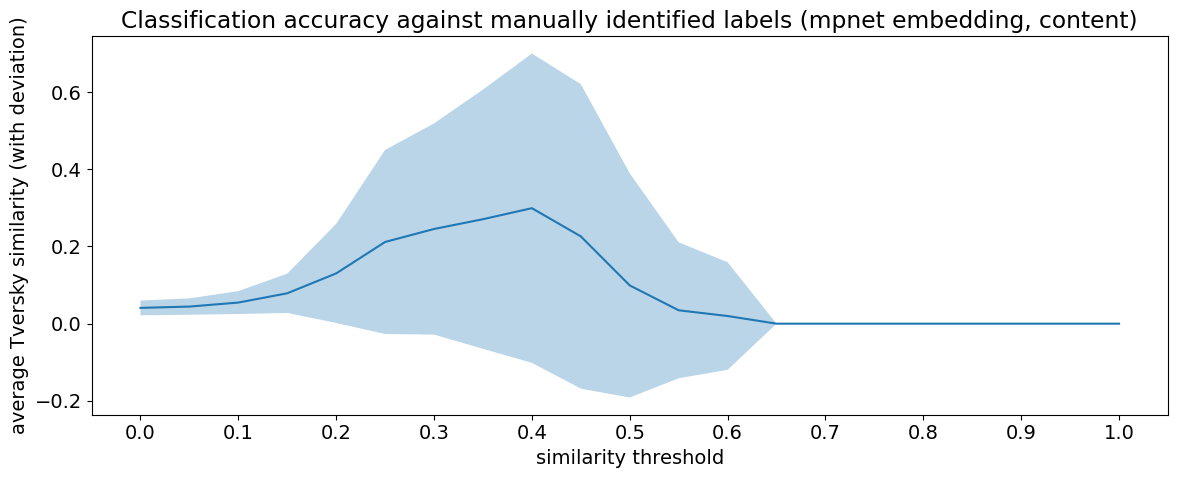

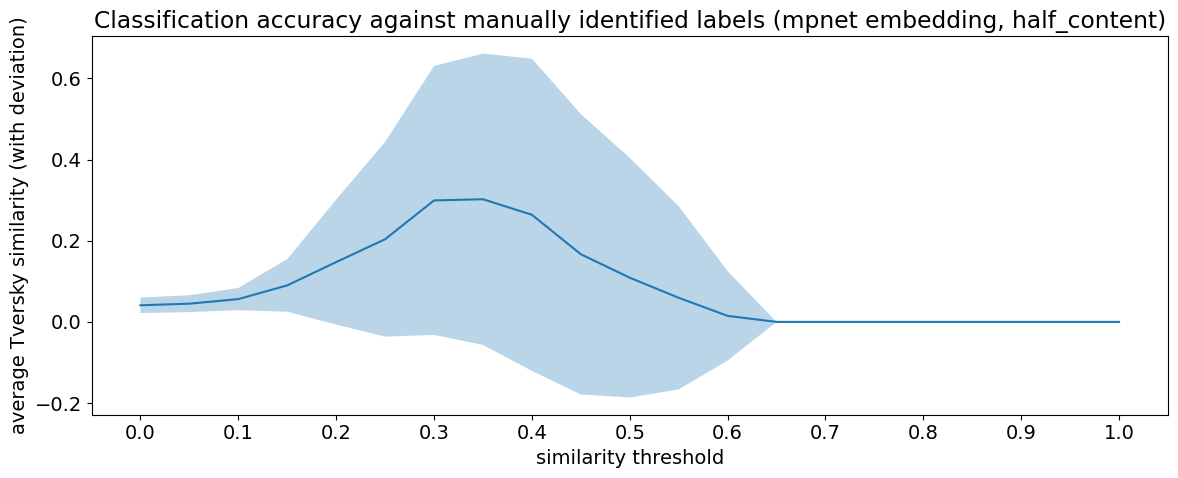

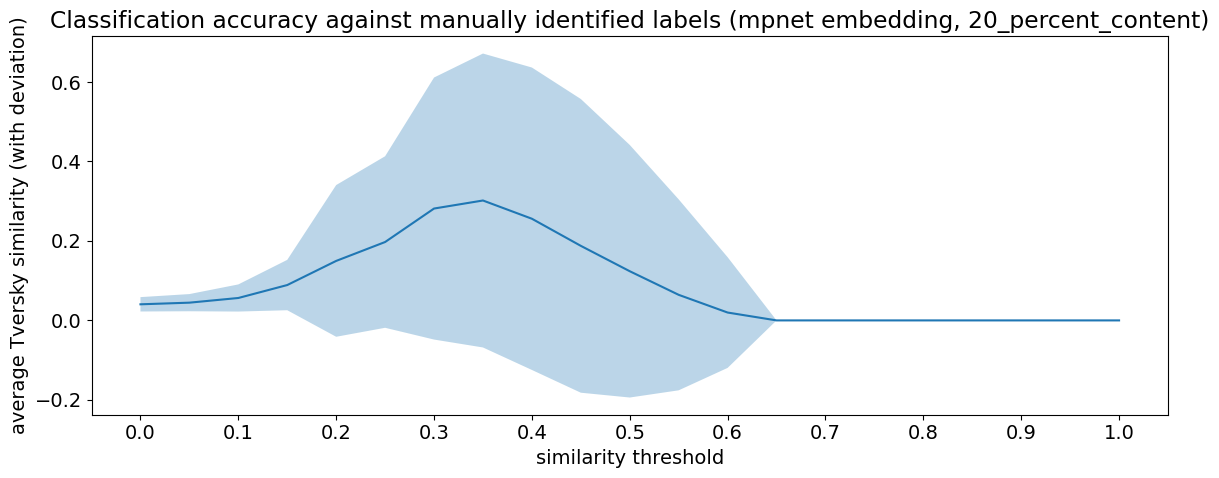

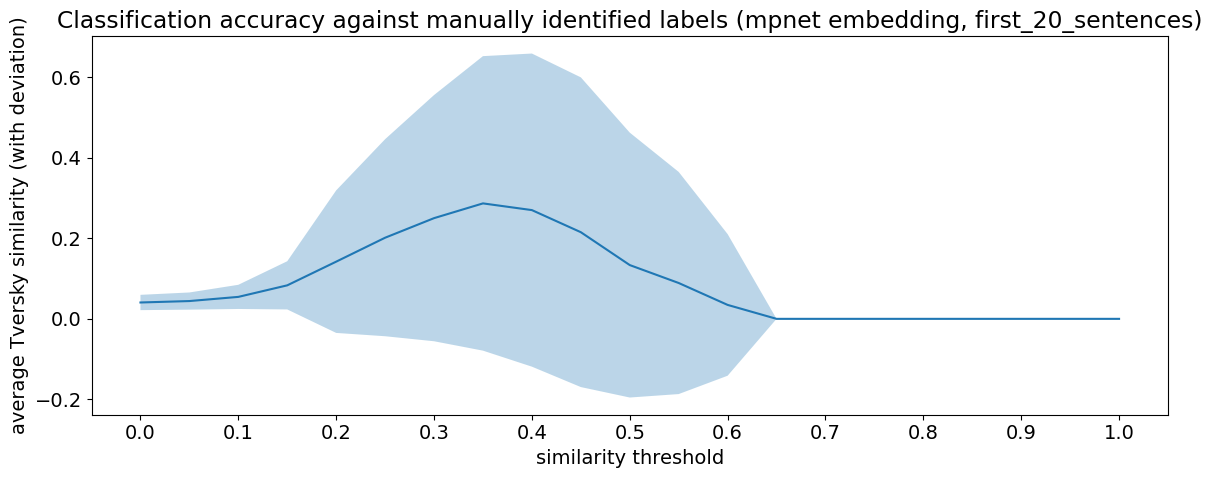

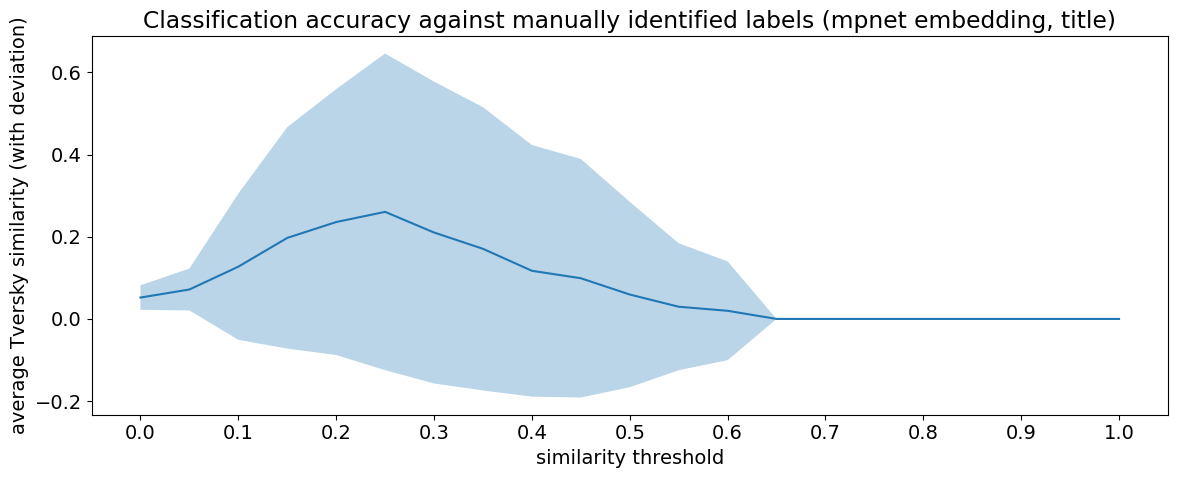

In [40]:
def assign_topics(topics: list[str], similarities: Tensor, threshold: float) -> set[str]:
  return {topic for t_i, topic in enumerate(topics) if similarities[t_i] >= threshold}

V = TypeVar('V')
def jaccard_sim(identified: set[V], actual: set[V]) -> float:
  return len(identified & actual) / len(identified | actual)
def false_pos(identified: set[V], actual: set[V]) -> int:
  return len(identified - actual)
def precision_sim(identified: set[V], actual: set[V]) -> float:
  return len(identified & actual) / len(identified)
def tversky_sim(fp_weight: float, fn_weight: float):
  def tver(identified: set[V], actual: set[V]) -> float:
    tp = len(identified & actual)
    return tp / (tp + fp_weight * len(identified - actual) + fn_weight * len(actual - identified))
  return tver

check_prop_topics = dict[tuple[int, str], set[str]]()
# collecting examples from the first batch of manually identified labels, for all projects
for proj_id, proj_topics in sep_topics.items():
  if proj_id not in {3, 4, 8}:
    for prop_id, prop_topics in proj_topics.items():
      p_key = (proj_id, prop_id)
      for topic in prop_topics:
        if p_key not in check_prop_topics: check_prop_topics[p_key] = set()
        check_prop_topics[p_key].add(topic)
# collecting examples from the second batch, for JEP
for meanings in jep_label_meanings_and_examples.values():
  for topic, examples in meanings:
    if topic in topic_explanations:
      for prop_id in examples:
        p_key = (6, prop_id)
        if p_key not in check_prop_topics: check_prop_topics[p_key] = set()
        check_prop_topics[p_key].add(topic)

check_prop_ids = list(check_prop_topics.keys())
check_revs = proposals_latest_revisions([(proj_id, prop_id) for proj_id, prop_id in check_prop_ids])

thresholds = np.linspace(0., 1., 21, dtype=float)
plt.rc('font', size=14)
for emb_strat in embedding_strats:
  sims = similarities_with_topics(check_revs, all_topics, mpnet_embedder, 'mpnet', emb_strat)
  # for idx, prop_id in enumerate(check_prop_ids):
  #   print(prop_id)
  #   print(check_prop_topics[prop_id])
  #   print(sorted([(s, topics_and_explanations[i][0]) for i, s in enumerate(sims[idx])], reverse=True))

  accuracies = np.array([[tversky_sim(2, 1)(
      assign_topics(all_topics, sims[p_i], thres),
      check_prop_topics[prop_id])
      for p_i, prop_id in enumerate(check_prop_ids)]
    for thres in thresholds])
  mean_accs = np.mean(accuracies, axis=1, dtype=float)
  stddev_accs = np.std(accuracies, axis=1, dtype=float)

  _ = plt.figure(figsize=(12, 5))
  _ = plt.plot(thresholds, mean_accs)
  _ = plt.fill_between(thresholds, mean_accs - stddev_accs, mean_accs + stddev_accs, alpha=0.3)
  _ = plt.title(f'Classification accuracy against manually identified labels (mpnet embedding, {emb_strat})')
  _ = plt.xticks(thresholds[::2])
  _ = plt.xlabel('similarity threshold')
  _ = plt.ylabel('average Tversky similarity (with deviation)')
  show_and_save(f'jacc_{emb_strat}')
plt.rcdefaults()

Setting the threshold and getting labels:

In [41]:
final_embed_strat = '20_percent_content'
final_thres = 0.35
final_topics = {proj_id: {
  prop_id: set[str]() for prop_id in project_proposals(proj_id)
} for proj_id in project_ids_to_explore}

for proj_id in project_ids_to_explore:
  if proj_id != 8: # kubernetes has separate topics
    proj_revs = project_latest_revisions(proj_id)
    sims = similarities_with_topics(proj_revs, all_topics, mpnet_embedder, 'mpnet', final_embed_strat)
    for p_i, rev in enumerate(proj_revs):
      # get topics from auto classification
      final_topics[proj_id][rev.proposal_id] |= assign_topics(all_topics, sims[p_i], final_thres)
      # get the meta topic if applicable
      if is_meta_sep(proj_id, rev.proposal_id):
        final_topics[proj_id][rev.proposal_id].add('meta')

# get topics from metadata if applicable
for prop in proposals_with_topics:
  final_topics[prop.project_id][prop.proposal_id] |= proposal_topics(prop)

Using the labels to compute statistics:

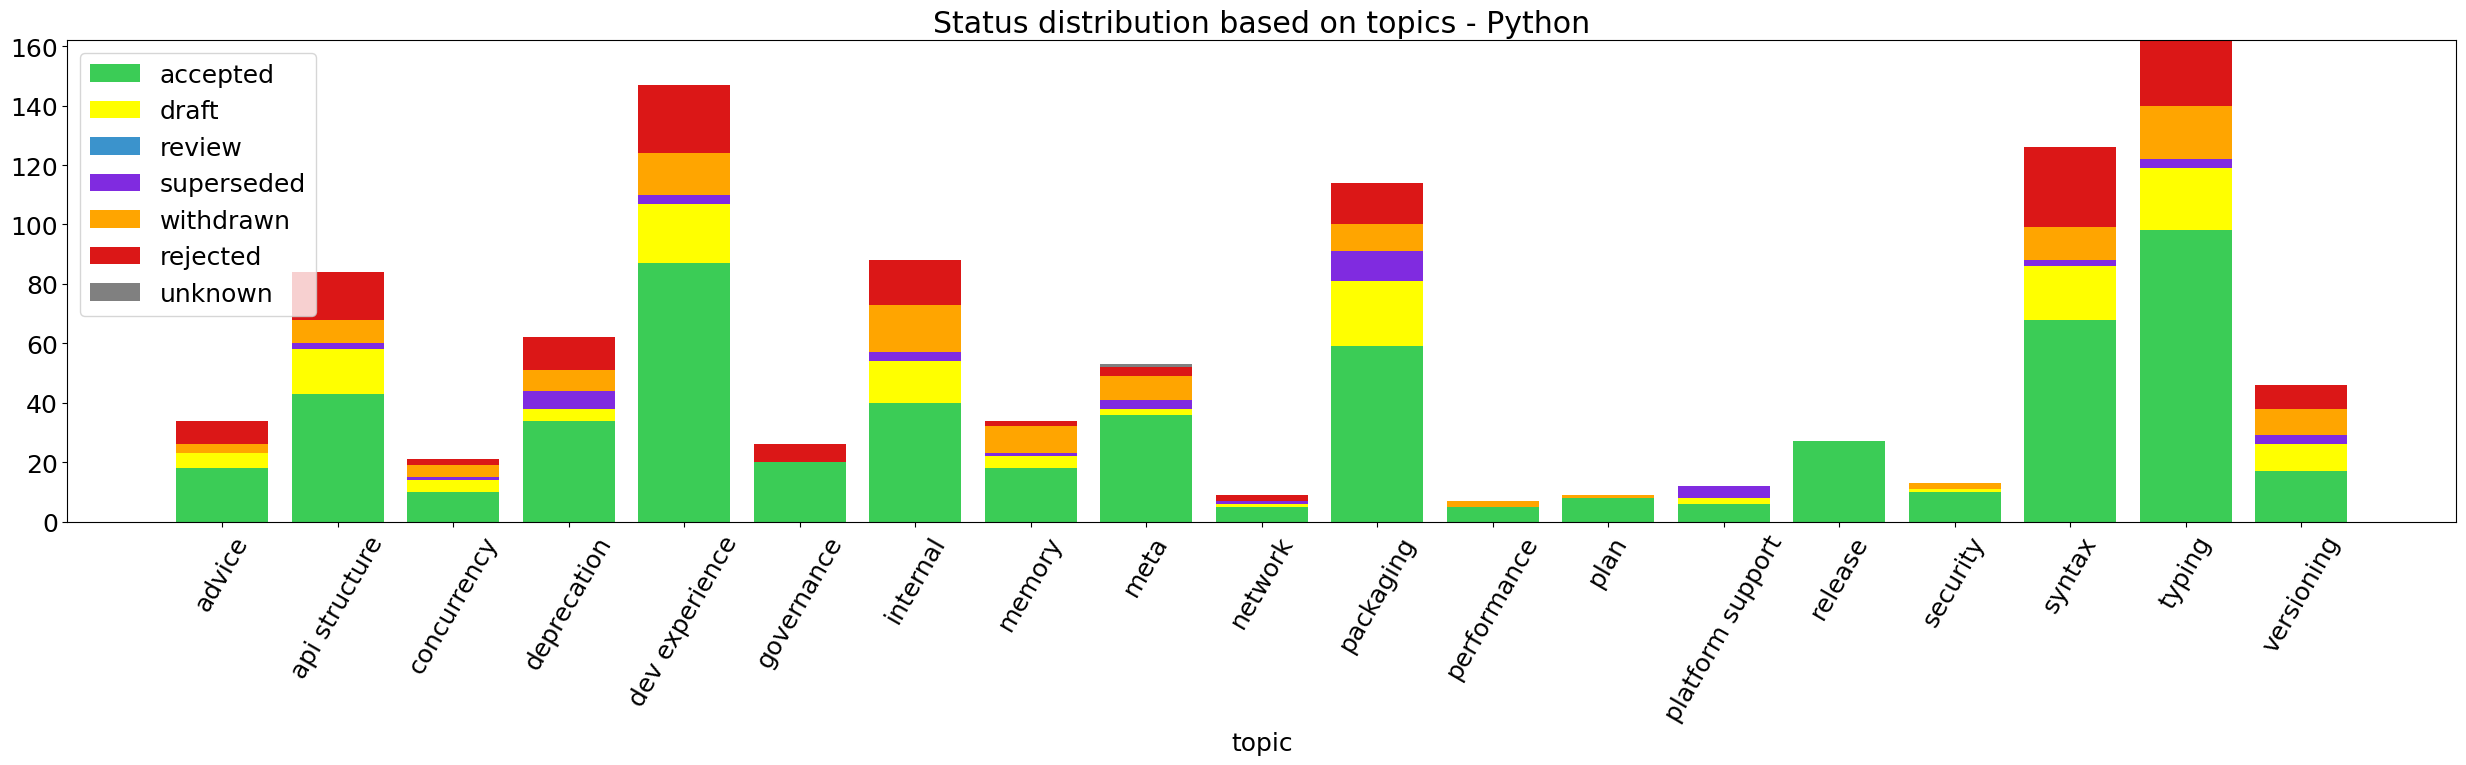

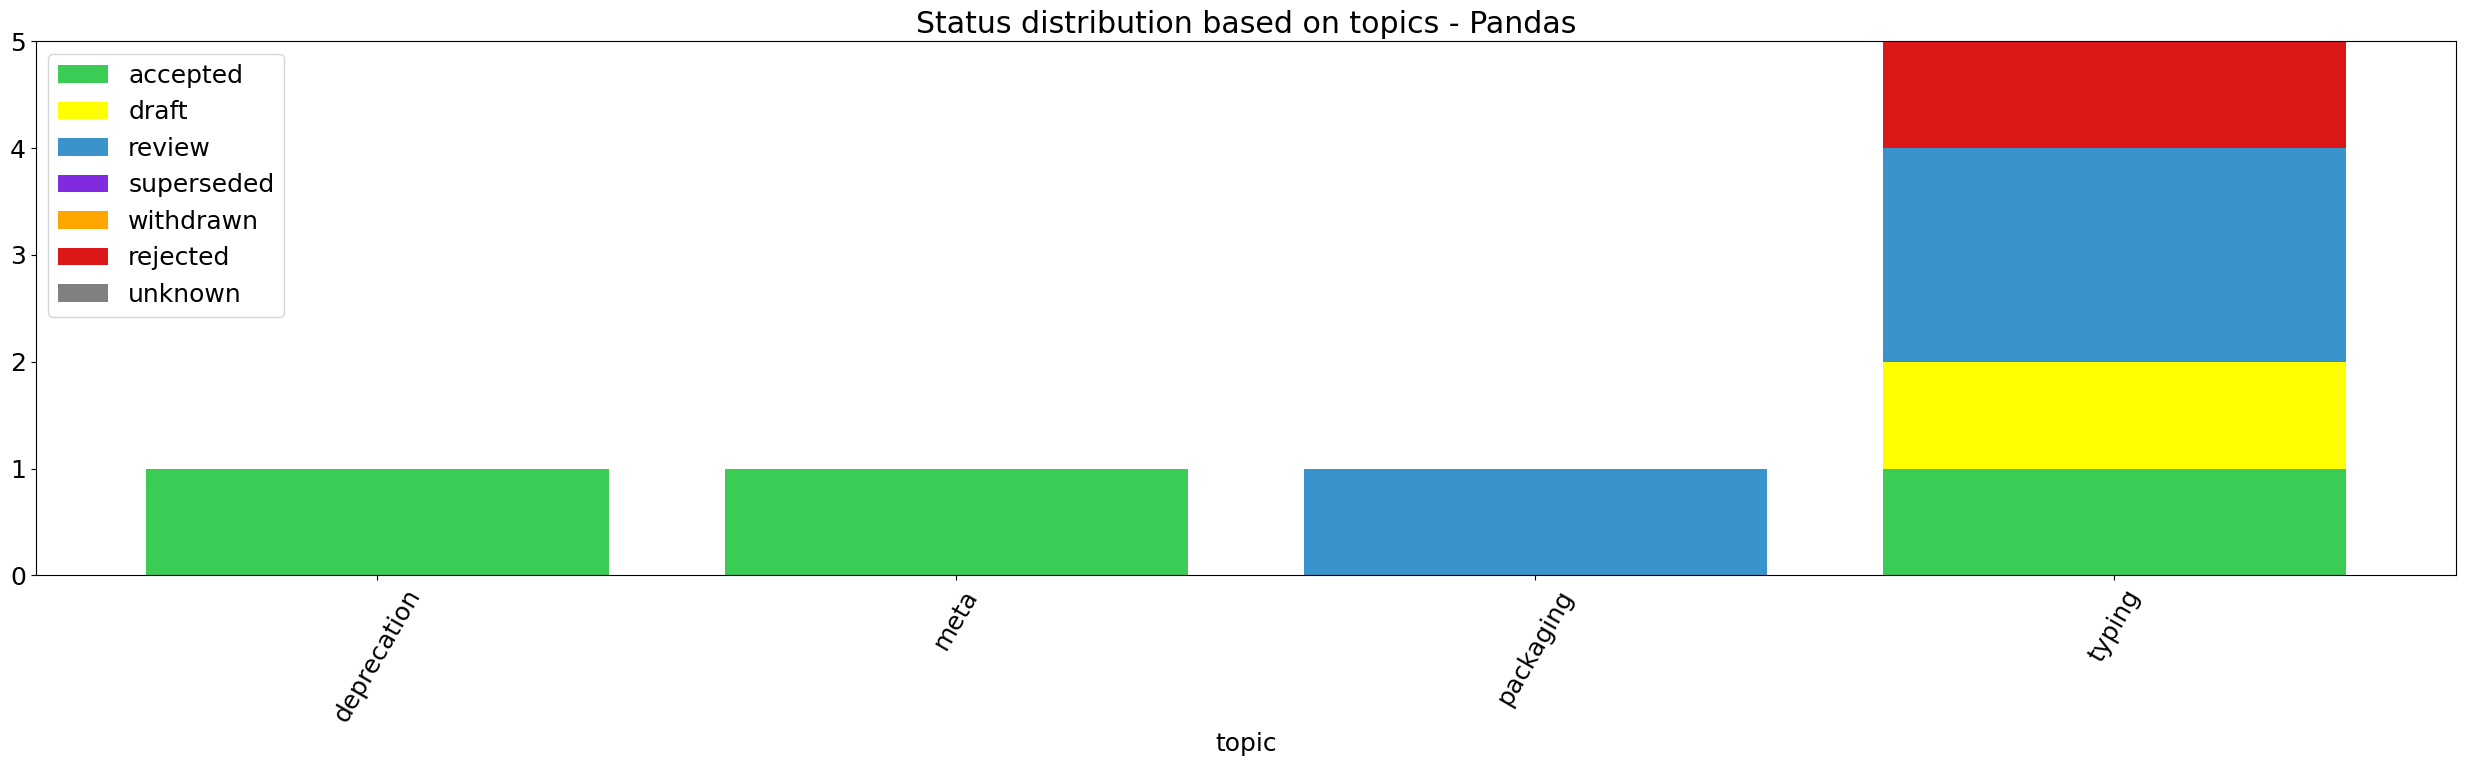

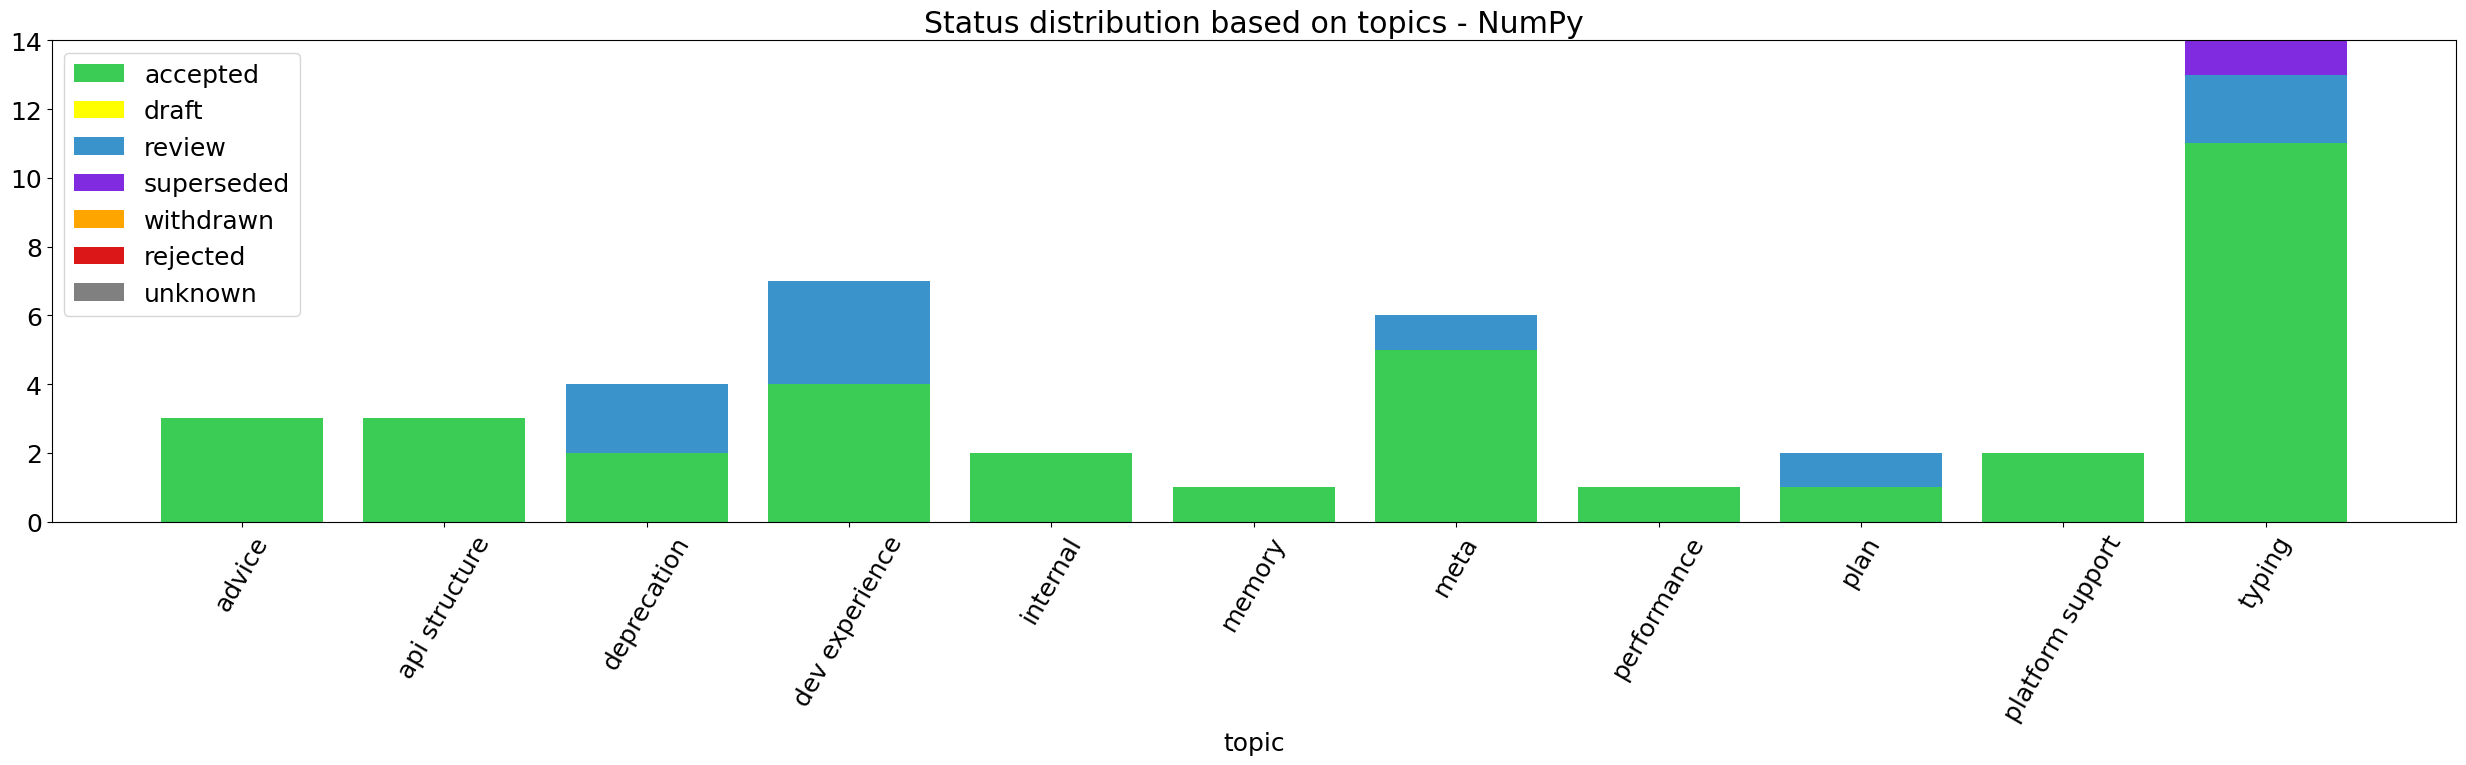

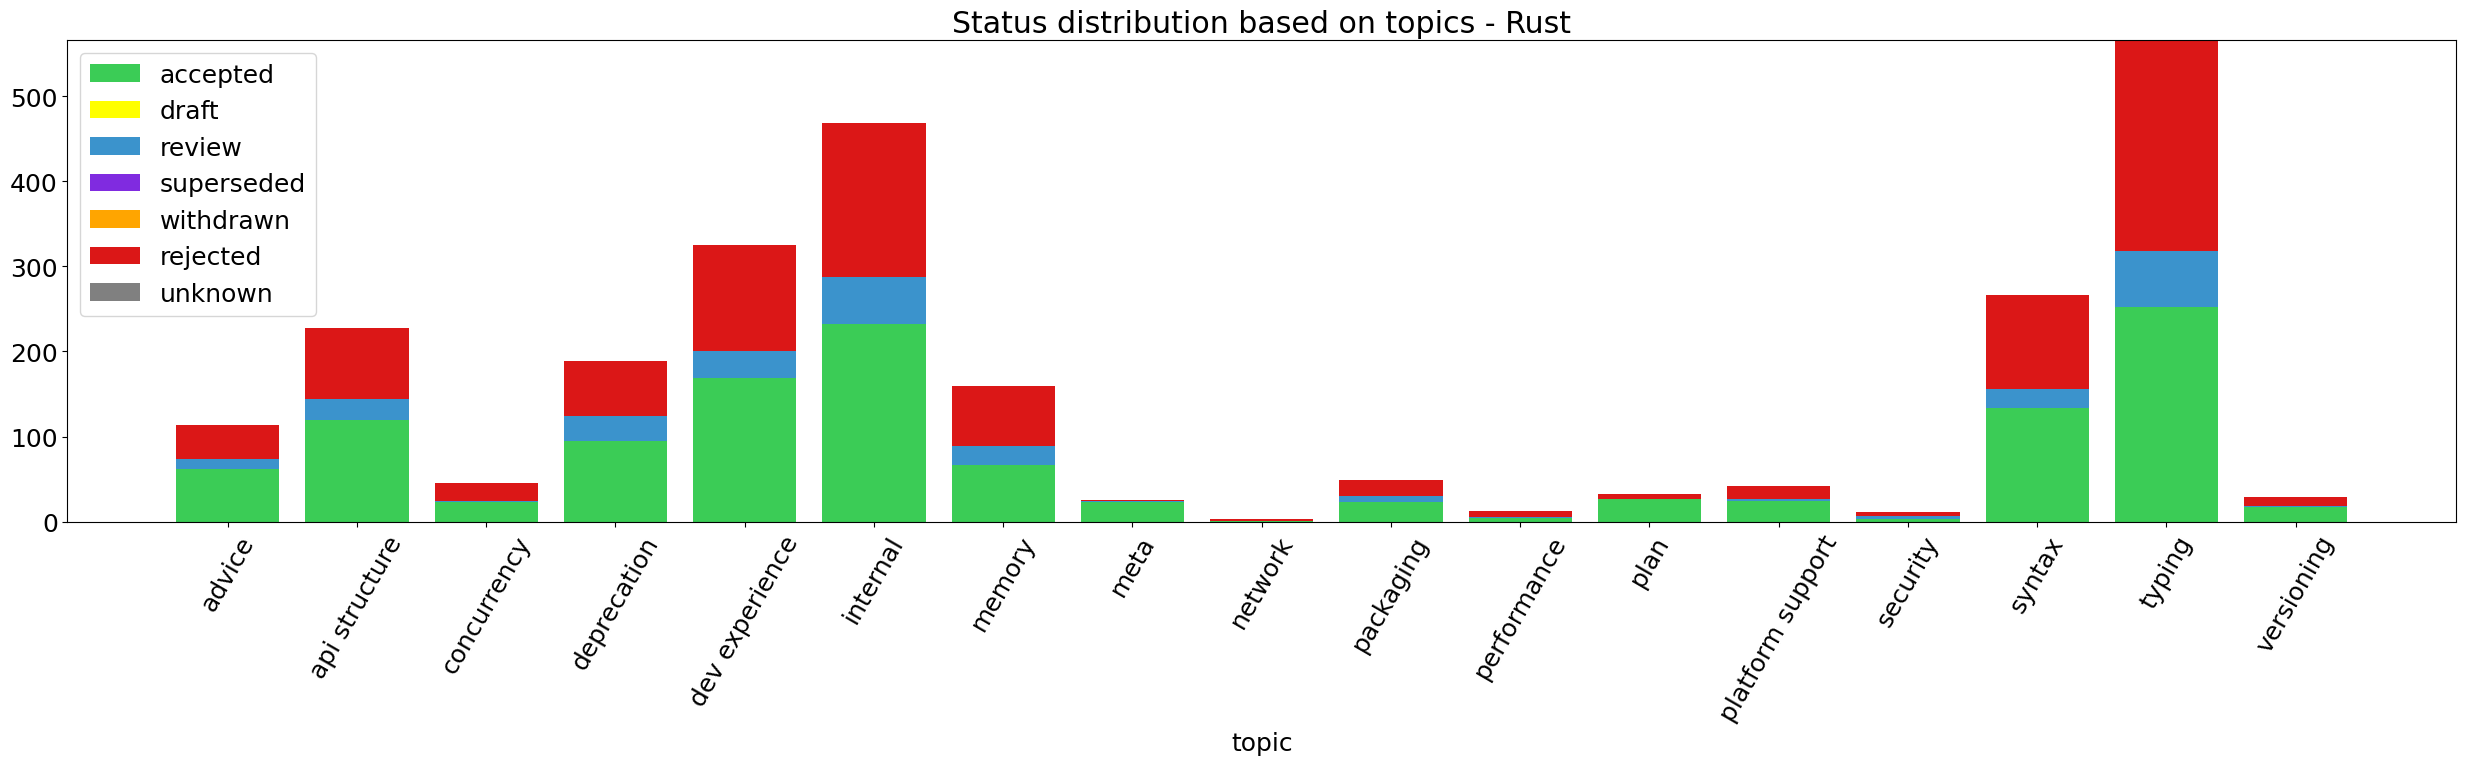

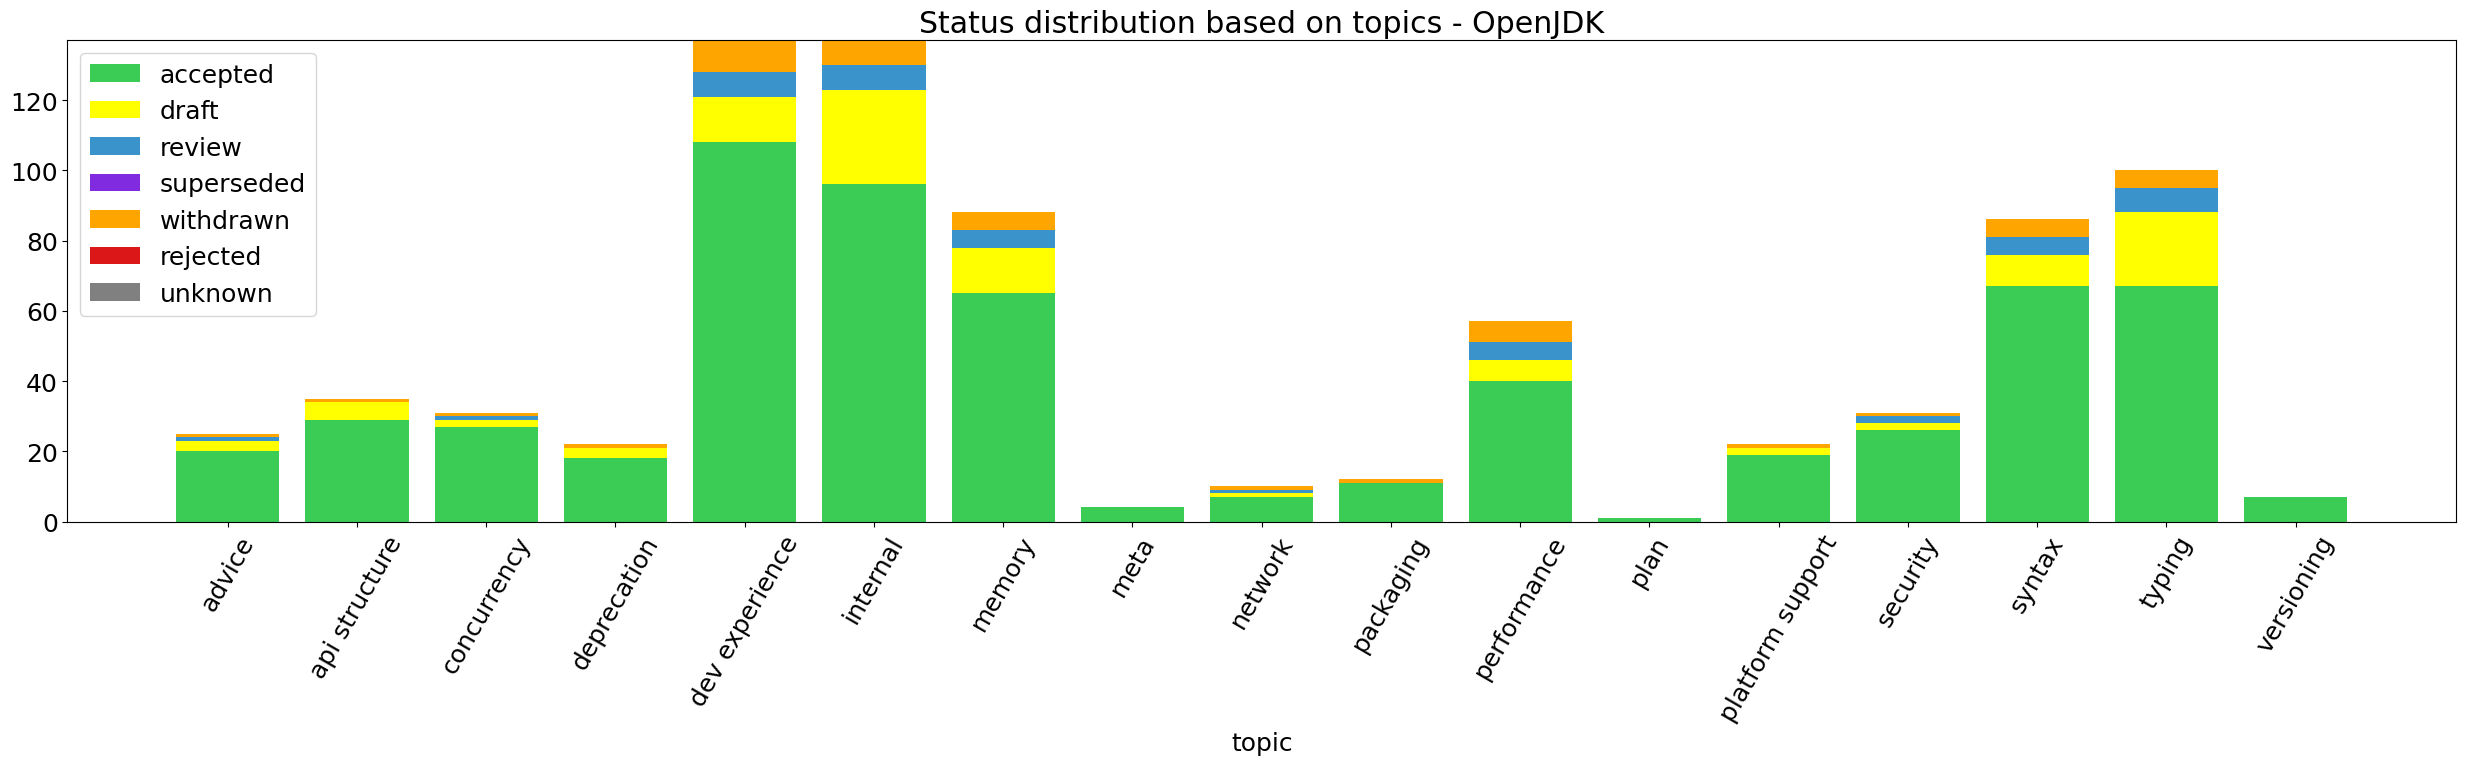

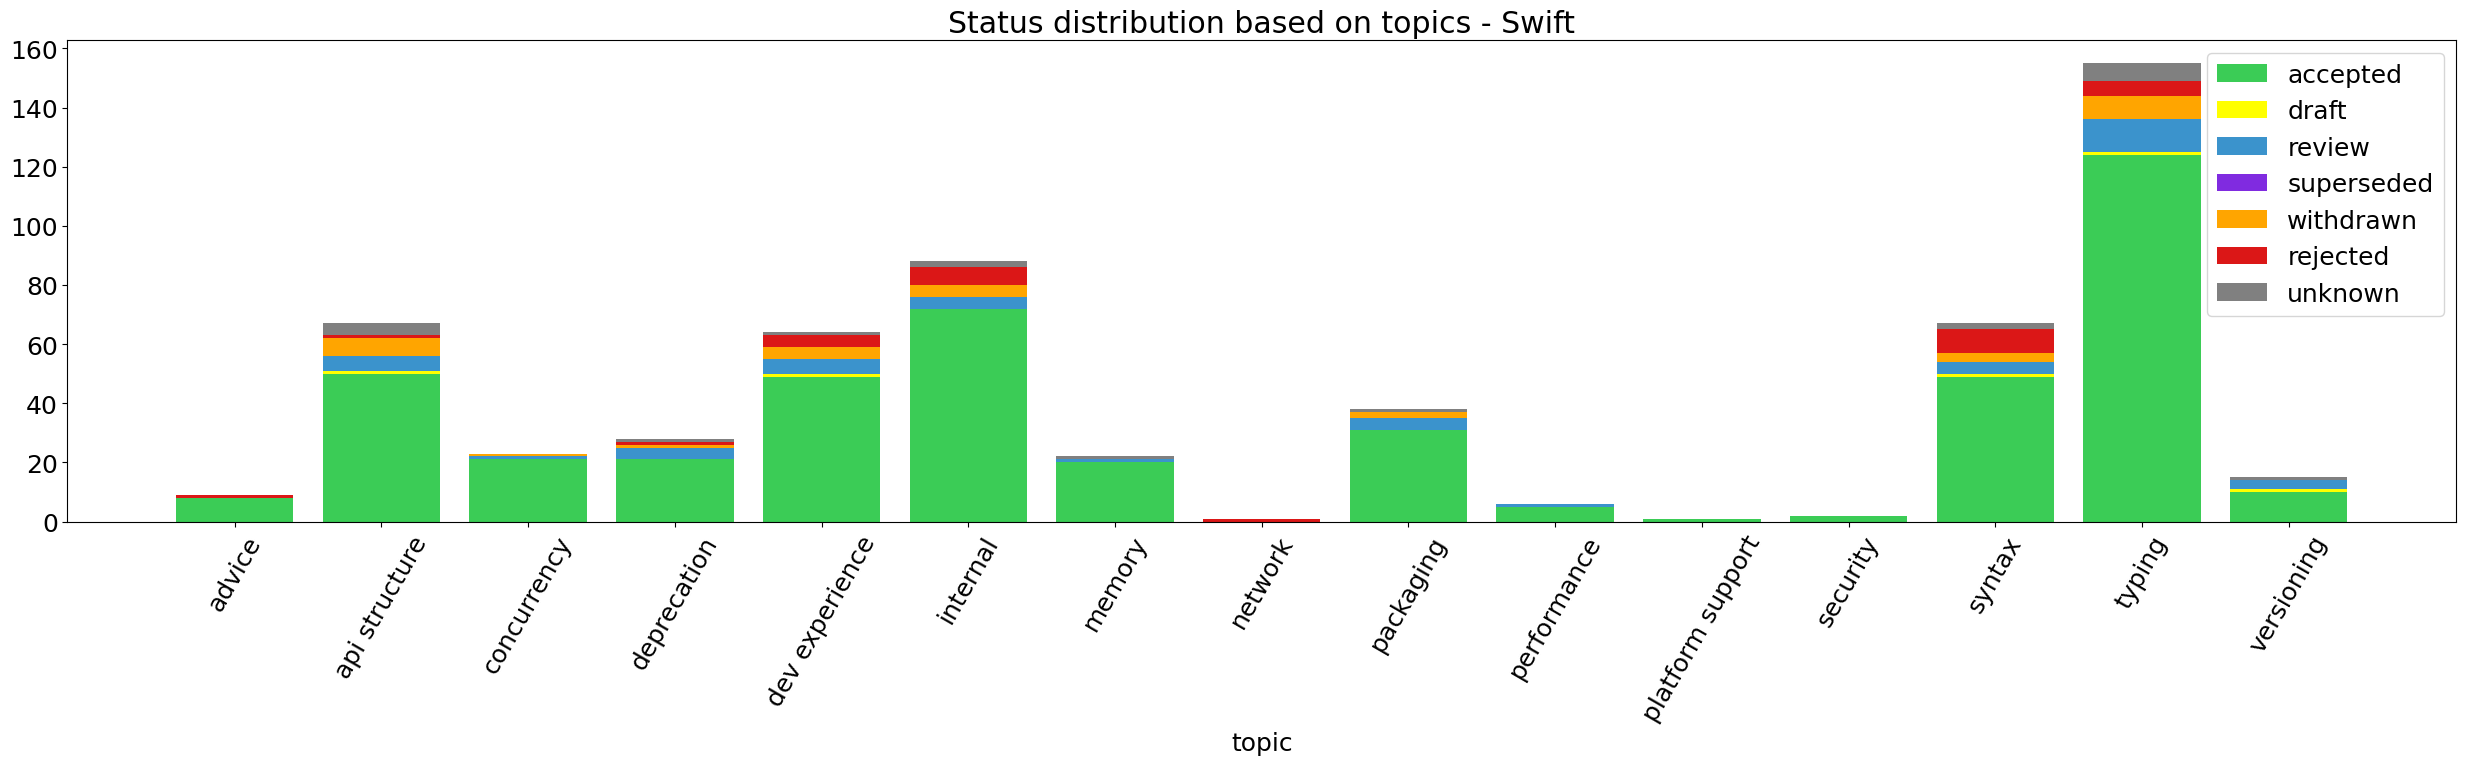

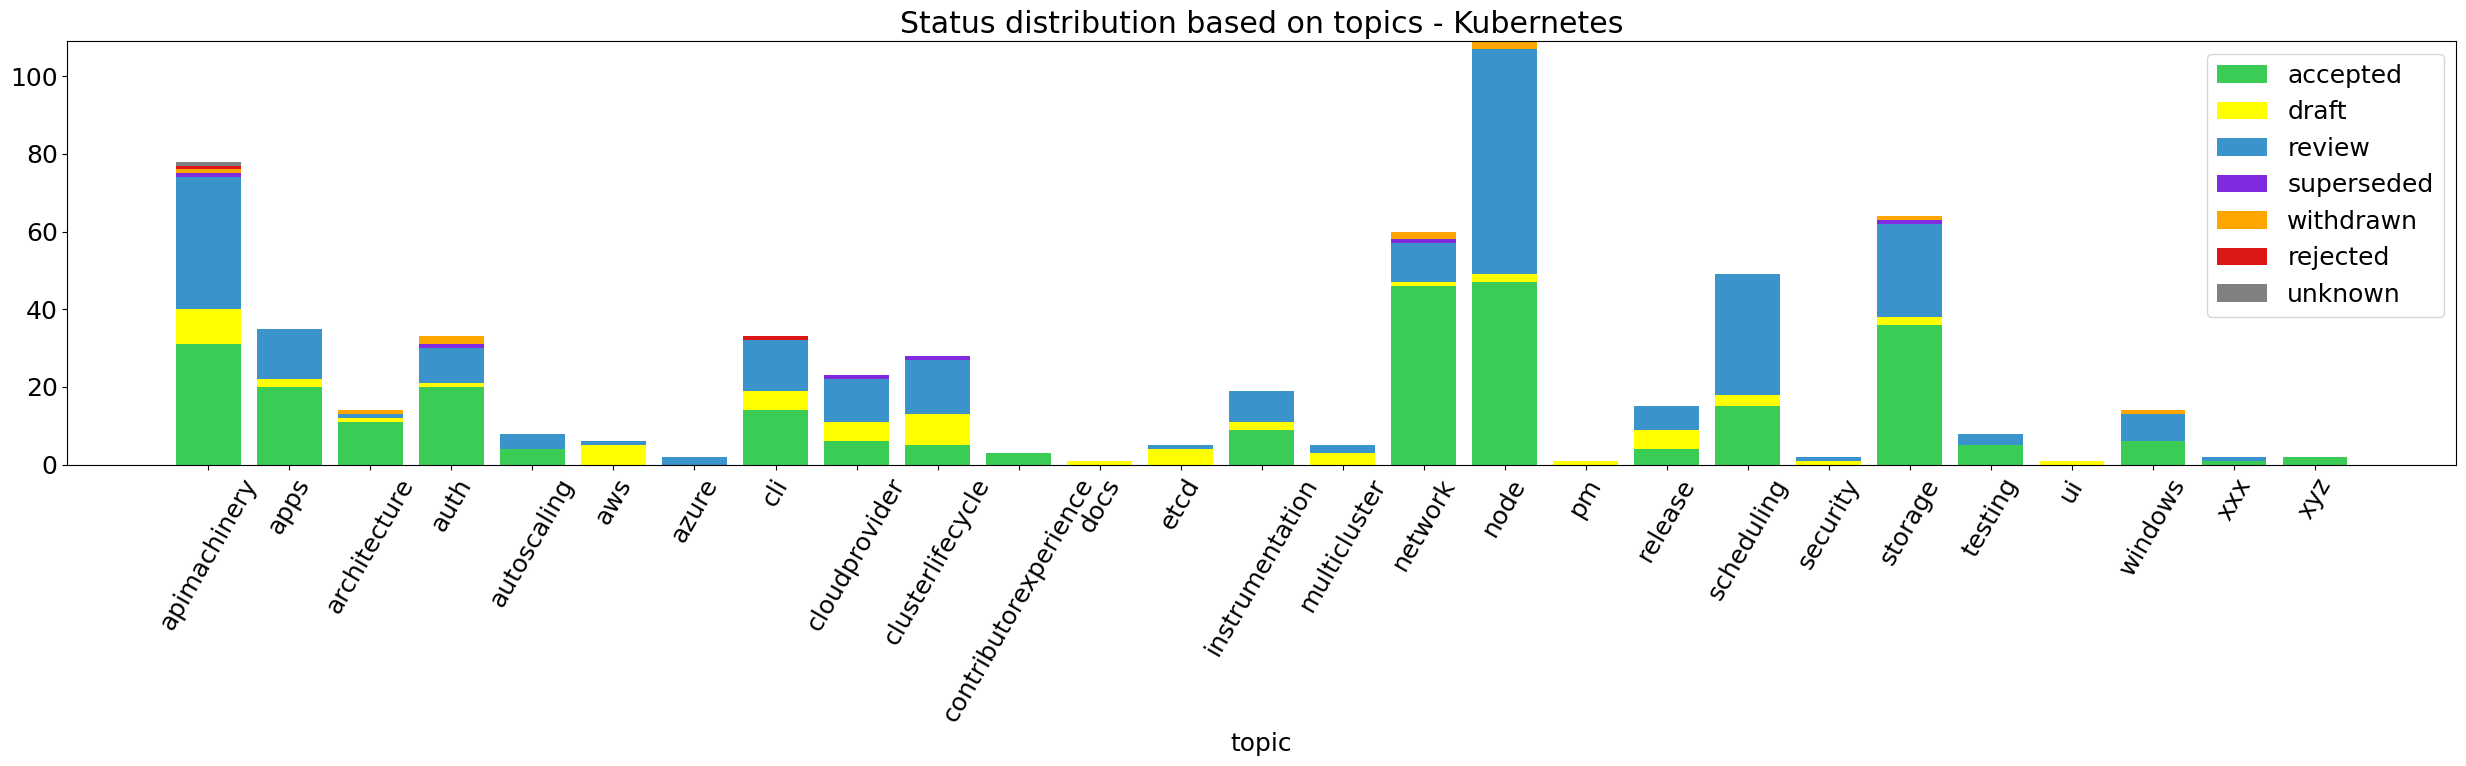

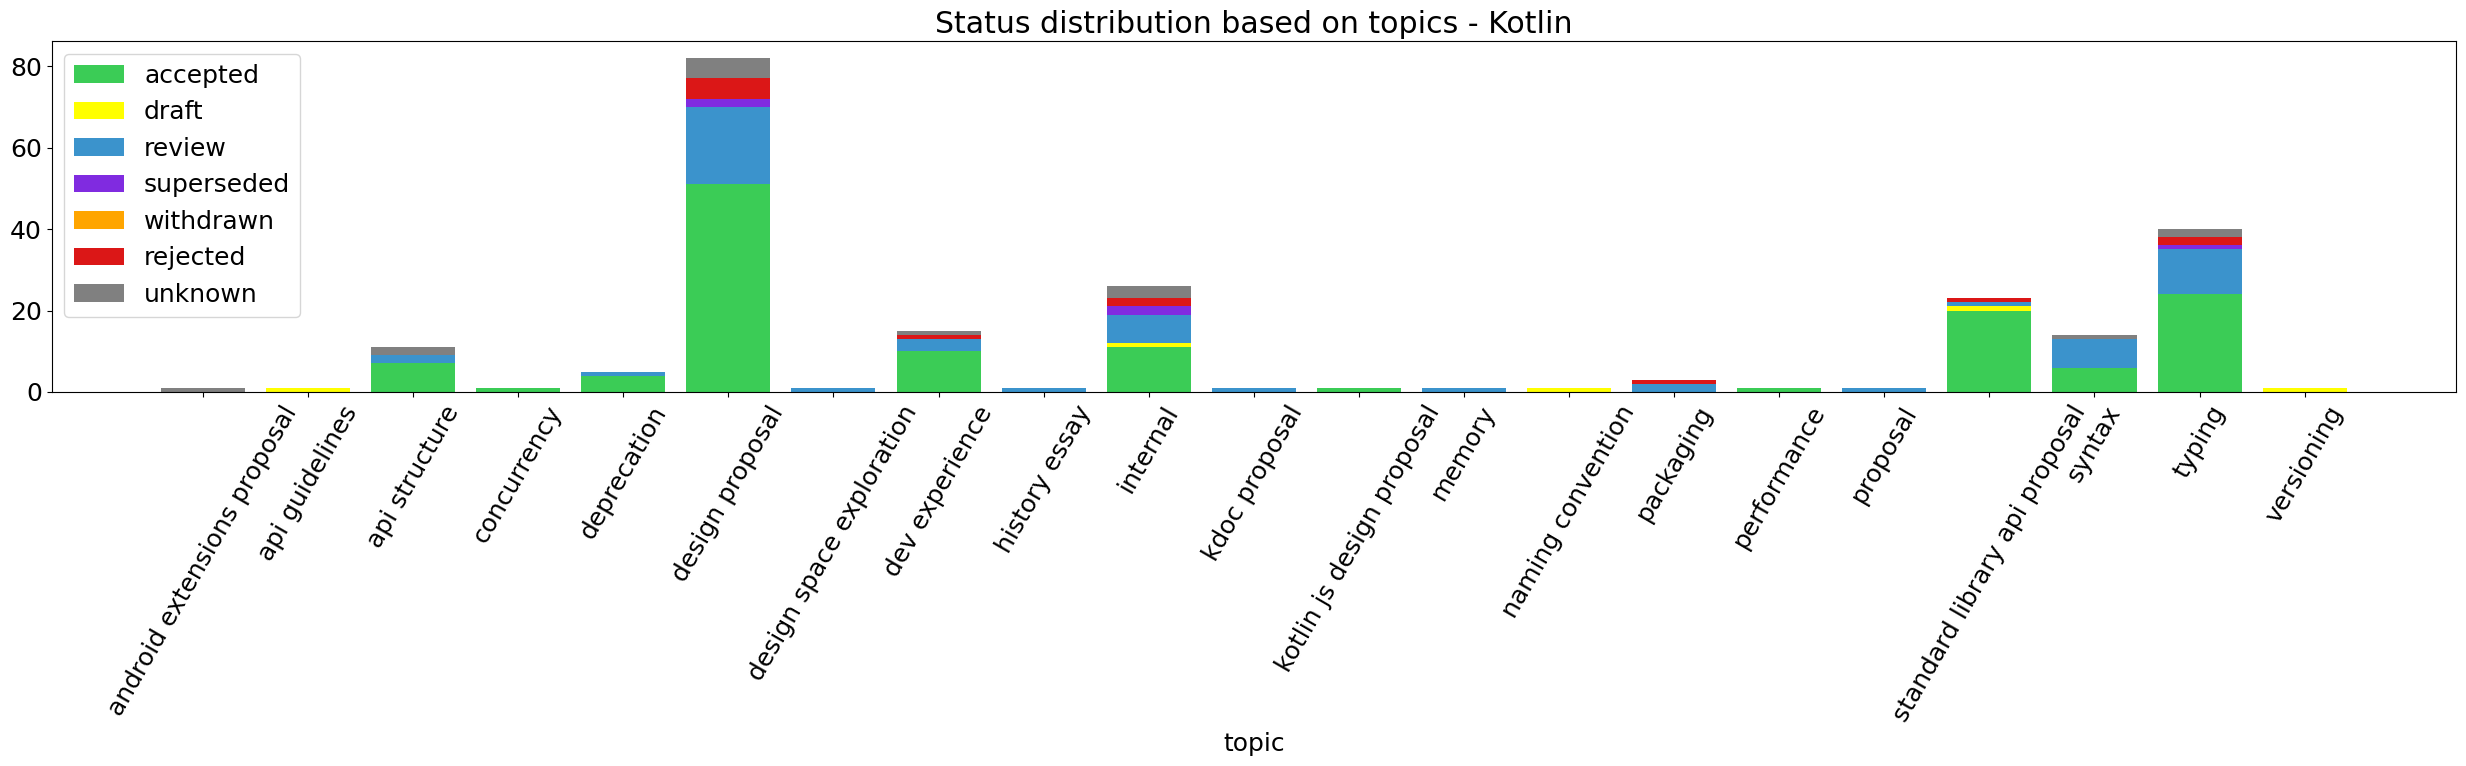

In [42]:
plt.rc('font', size=18)
for proj_id, props_topics in final_topics.items():
  project = projects[proj_id]
  stat_topic_counts = {stat: Counter[str]() for stat in NormalisedStatus}
  for prop_id, topics in props_topics.items():
    curr_stat = proposal_latest_status(proj_id, prop_id)
    if curr_stat:
      topic_counts = stat_topic_counts[curr_stat[1]]
      for topic in topics:
        topic_counts[topic] += 1
  all_proj_topics = sorted(list({topic for topic_counts in stat_topic_counts.values() for topic in topic_counts}))
  cumul_topic_counts = Counter[str]()

  plt.figure(figsize=(25, 8))
  for stat in NormalisedStatus:
    topic_counts = stat_topic_counts[stat]
    _ = plt.bar(all_proj_topics, [topic_counts[topic] for topic in all_proj_topics],
      bottom=[cumul_topic_counts[topic] for topic in all_proj_topics],
      label=stat.value, color=status_color[stat])
    cumul_topic_counts += topic_counts

  _ = plt.xticks(rotation=60)
  _ = plt.xlabel('topic')
  _ = plt.title(f'Status distribution based on topics - {project.project_name}')
  _ = plt.legend()
  show_and_save(f'topic_stats_{project.project_name}')
plt.rcdefaults()

In [43]:
for pid, ts in final_topics[6].items():
  if 'platform support' in ts: print(pid)

102
175
188
191
208
237
247
253
272
294
297
343
365
388
389
412
419
422
442
454
501
8288293


In [44]:
final_stats = {NormalisedStatus.accepted, NormalisedStatus.rejected, NormalisedStatus.withdrawn, NormalisedStatus.superseded}

In [72]:
from sklearn.linear_model import LogisticRegression
from statsmodels.api import Logit

for proj_id in [0]:
  prop_ids = project_proposals(proj_id)
  finalised_props = [(prop_id, proposal_current_status(proj_id, prop_id)) for prop_id in prop_ids]
  # finalised_props = [(prop_id, stat) for prop_id, stat in finalised_props if stat in final_stats]

  props_topics = final_topics[proj_id]
  all_proj_topics = sorted(list({topic for prop_id, _ in finalised_props for topic in props_topics[prop_id]}))
  print(all_proj_topics)
  X_topics = np.array([[1 if topic in props_topics[prop_id] else 0 for topic in all_proj_topics] for prop_id, _ in finalised_props])
  print(X_topics)
  y_accept = np.array([1 if stat == NormalisedStatus.accepted else 0 for _, stat in finalised_props])
  print(y_accept)
  reg_model = Logit(y_accept, X_topics)
  reg_res = reg_model.fit()
  print([(topic, float(reg_res.params[i]), float(reg_res.pvalues[i])) for i, topic in enumerate(all_proj_topics)])
  # reg_model = LogisticRegression(random_state=random_seed)
  # reg_model = reg_model.fit(X_topics, y_accept)
  # print(reg_model.get_params())

['advice', 'api structure', 'concurrency', 'deprecation', 'dev experience', 'governance', 'internal', 'memory', 'meta', 'network', 'packaging', 'performance', 'plan', 'platform support', 'release', 'security', 'syntax', 'typing', 'versioning']
[[0 0 0 ... 0 0 0]
 [1 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [1 0 0 ... 0 0 0]]
[1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 0 1 0 1 0 1 1 0 0 0 0 0 1 0 0 1 1 0 0 1 0 1
 0 0 1 1 0 1 1 0 1 0 1 1 1 1 1 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 0 1 0 1 0 0 1
 1 0 1 1 0 0 0 0 0 0 0 1 1 1 0 0 1 1 1 0 0 1 1 0 1 0 1 0 1 1 0 1 1 0 0 0 0
 0 0 0 1 0 1 1 1 1 0 0 1 0 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0
 1 1 0 1 1 0 1 0 0 0 1 0 1 0 0 1 1 0 1 1 0 1 1 0 0 0 1 0 0 1 0 0 1 1 1 0 0
 1 0 0 1 1 1 0 0 1 0 1 0 1 0 1 0 0 1 1 0 0 1 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0
 0 1 0 0 0 0 1 1 0 0 1 1 1 0 1 1 1 0 0 0 1 0 0 0 1 1 1 1 1 1 1 0 1 0 1 0 0
 1 1 1 0 1 1 0 1 1 1 1 0 0 1 1 1 1 0 0 0 0 1 1 0 0 0 1 0 0 1 0 1 1 0 1 1 0
 0 1 1 0 0 1 1 0 1 1 1 1 0 0 0 1 1 1

/home/person/Projects/cse3000-sep/rq4-nep-jep/.venv/lib/python3.14/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## LLM classification

In [73]:
from google import genai
from google.genai.errors import ClientError

gemini_model = genai.Client(api_key=os.getenv('GEMINI_API_KEY'))

GEMINI_PROMPT = """
You are an expert developer specializing in {project_name}. Your task is to categorize {project_name} enhancement proposals. Analyze the following information for the given proposal:

* **Title:** The concise summary of the proposal.
* **Description:** The detailed explanation of the proposal's nature and purpose.

Assign one or more of the following categories to the proposal:

{categories}

**Input:**

* Title: {title}
* Description: {description}


**Output:**

Just answer with the category without any explanation like below
Category(ies): CAT1, CAT2, CAT3, ... (comma-separated if multiple)

**Important Considerations:**

* Be precise and focus on the primary goal of the proposal.
* If the purpose of a proposal is unclear, prioritize the most likely category based on the available information.
* Use your expertise in {project_name} to infer the context of proposals when necessary. 

"""

all_topic_explanations = topic_explanations | {
  'meta': 'About software enhancement proposals themselves, governance, for {project_name}, {sep_name}'}

def get_gemini_proposal_labels(project_id: int, proposal_id: str) -> list[str]:
  save_dir = f'cache/prompt_answers/{project_id}'
  os.makedirs(save_dir, exist_ok=True)
  save_file = f'{save_dir}/{proposal_id}.npy'
  try:
    return np.load(save_file)
  except:
    project = projects[project_id]
    categories_expl = '\n'.join(f'* **{topic}:** {explanation.format(project_name=project.project_name, sep_name=project.enhancement_proposal_name)}.'
      for topic, explanation in all_topic_explanations.items())
    prop = proposal_latest_revision(project_id, proposal_id)
    assert prop is not None
    fmt_pmpt = GEMINI_PROMPT.format(project_name=project.project_name, title=prop.title,
      description=' '.join(tokenize_content(20)(sanitize_content(project_id, prop.content))),
      categories=categories_expl)
    response = gemini_model.models.generate_content(model='gemini-3.5-flash', contents=fmt_pmpt,
      config=genai.types.GenerateContentConfig(temperature=0))
    llm_answer = str(response.text)
    llm_labels = llm_answer.replace('Category(ies): ', '').split(', ')
    np.save(save_file, llm_labels)
    return llm_labels

In [74]:
# try:
#   get_gemini_proposal_labels(2, '5')
# except ClientError as e:
#   print(str(e.args[0]))
#   print(re.match(r".*retryDelay': '([0-9]*)", str(e.args[0])).groups()[0])

In [75]:
# import time

# for proj_id in project_ids_to_explore:
#   if proj_id == 0:
#     for prop_id in project_proposals(proj_id):
#       result = None
#       while result is None:
#         try:
#           result = get_gemini_proposal_labels(proj_id, prop_id)
#         except ClientError as e:
#           err_m = re.match(r".*retryDelay': '([0-9]*)", str(e.args[0]))
#           print(err_m)
#           if err_m is not None:
#             print(err_m.groups())
#             time.sleep(int(err_m.groups()[0]) + 1)
#           else:
#             time.sleep(30)
#         except BaseException as e:
#           print('other exception', e)
#           time.sleep(30)

In [76]:
# for f in os.listdir('cache/prompt_answers/0'):
#   print(f, np.load(f'cache/prompt_answers/0/{f}'))

## Time analysis

Looking for acceptance patterns in time

In [77]:
def proposal_first_mention(project_id: int, proposal_id: str) -> datetime | None:
  first_rev = session.scalar(select(ProposalRevision.created_at)
    .where(ProposalRevision.project_id.is_(project_id))
    .where(ProposalRevision.proposal_id.is_(proposal_id))
    .order_by(ProposalRevision.created_at)
    .limit(1))
  first_stat = session.scalar(select(ProposalStatus.created_at)
    .where(ProposalStatus.project_id.is_(project_id))
    .where(ProposalStatus.proposal_id.is_(proposal_id))
    .order_by(ProposalStatus.created_at)
    .limit(1))
  if first_rev is None:
    return first_stat
  if first_stat is None:
    return first_rev
  return min(first_rev, first_stat)

def proposal_first_such_status(project_id: int, proposal_id: str, stat: NormalisedStatus) -> datetime | None:
  return session.scalar(select(ProposalStatus.created_at)
    .where(ProposalStatus.project_id.is_(project_id))
    .where(ProposalStatus.proposal_id.is_(proposal_id))
    .where(ProposalStatus.normalised_status.is_(stat))
    .order_by(ProposalStatus.created_at)
    .limit(1))

def proposal_first_verdict(project_id: int, proposal_id: str) -> datetime | None:
  latest_status = proposal_latest_status(project_id, proposal_id)
  if latest_status is None:
    return None
  return proposal_first_such_status(project_id, proposal_id, latest_status[1])

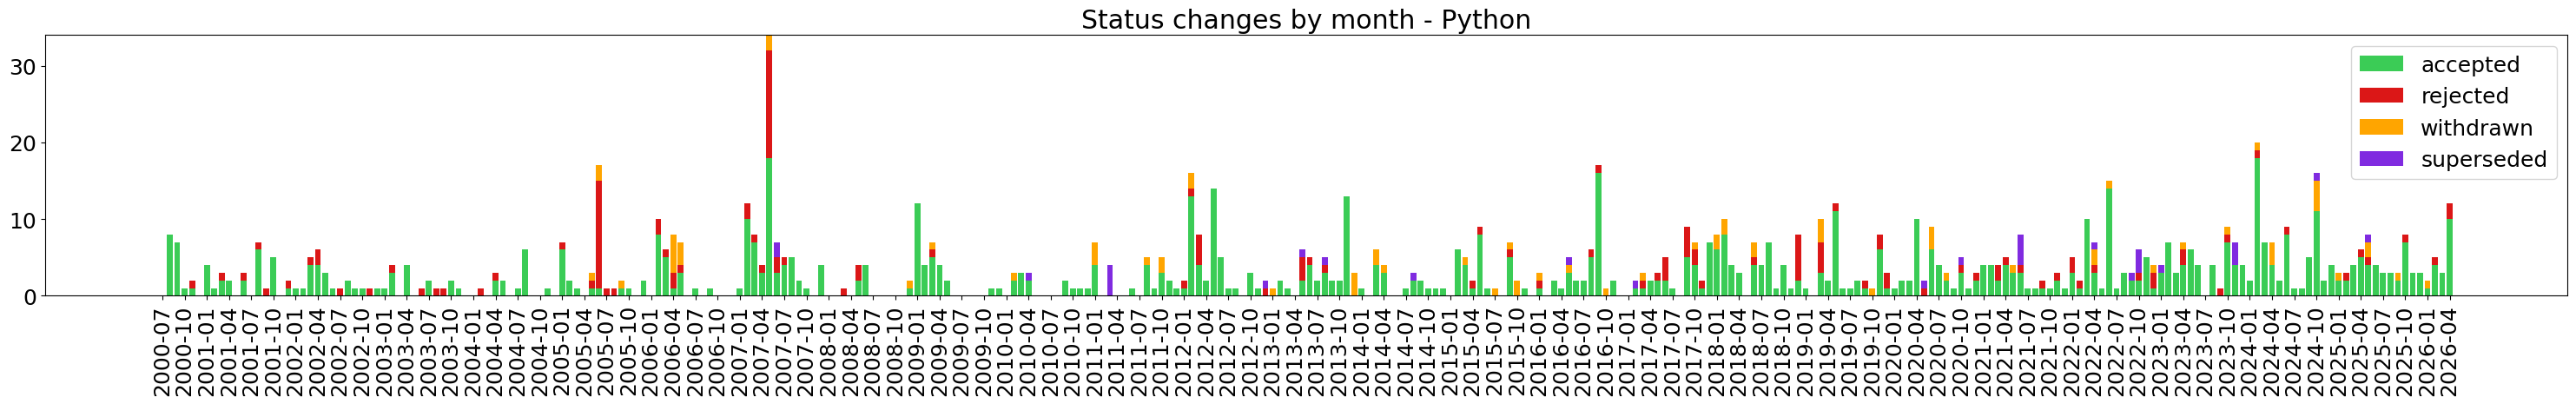

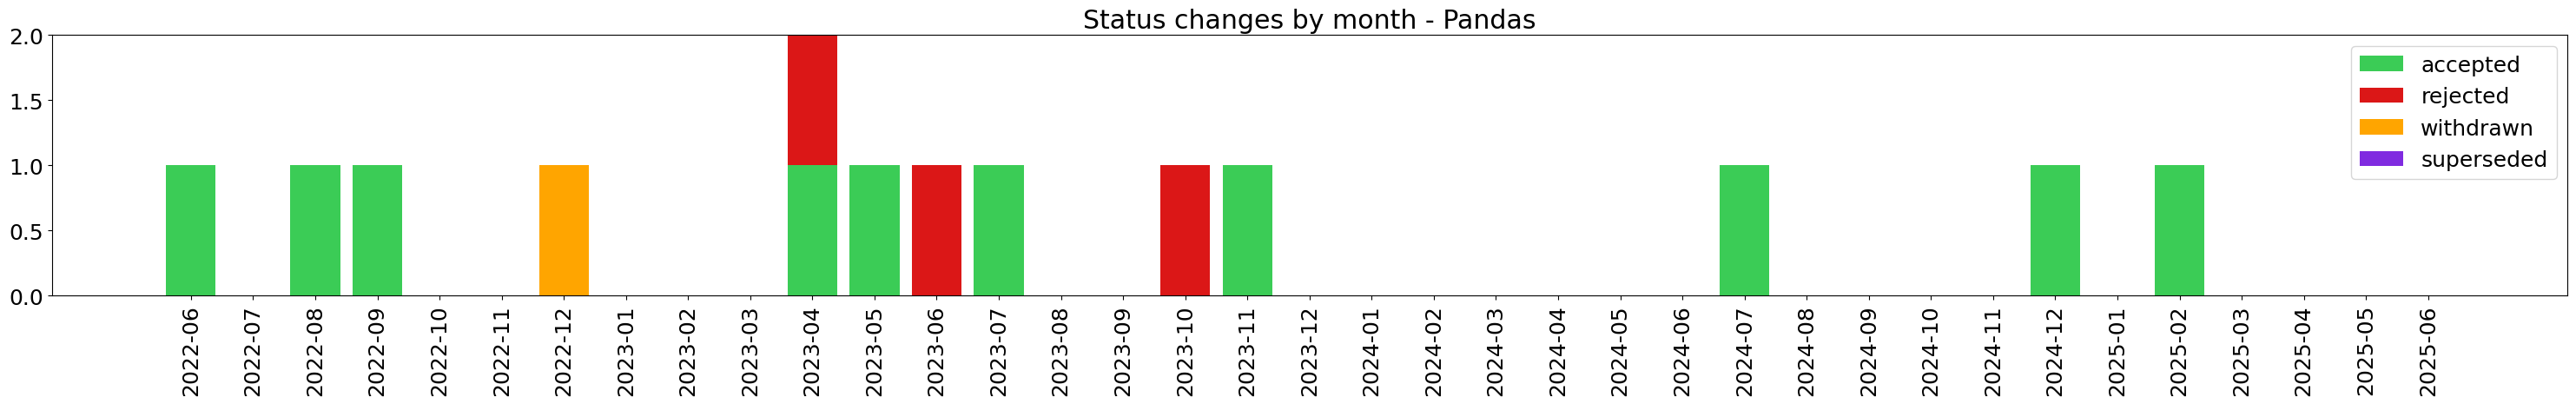

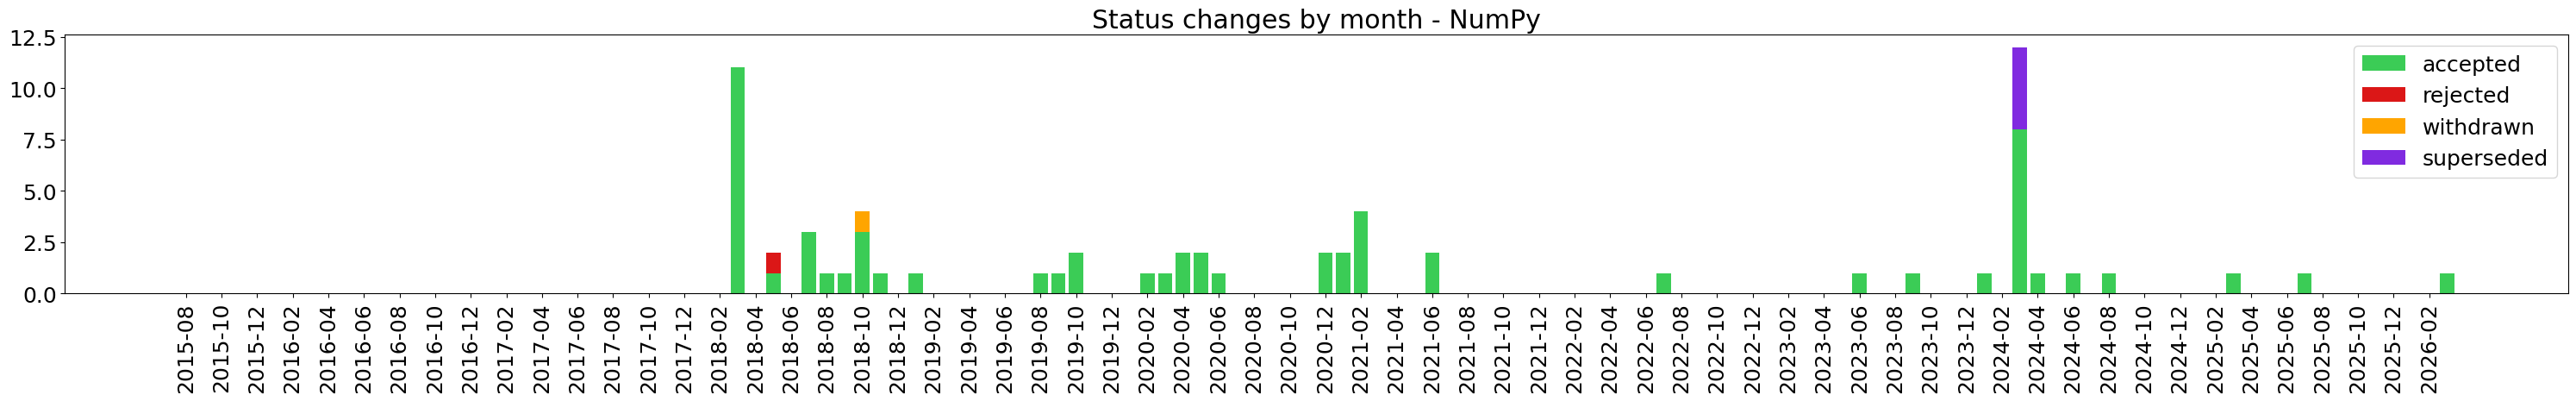

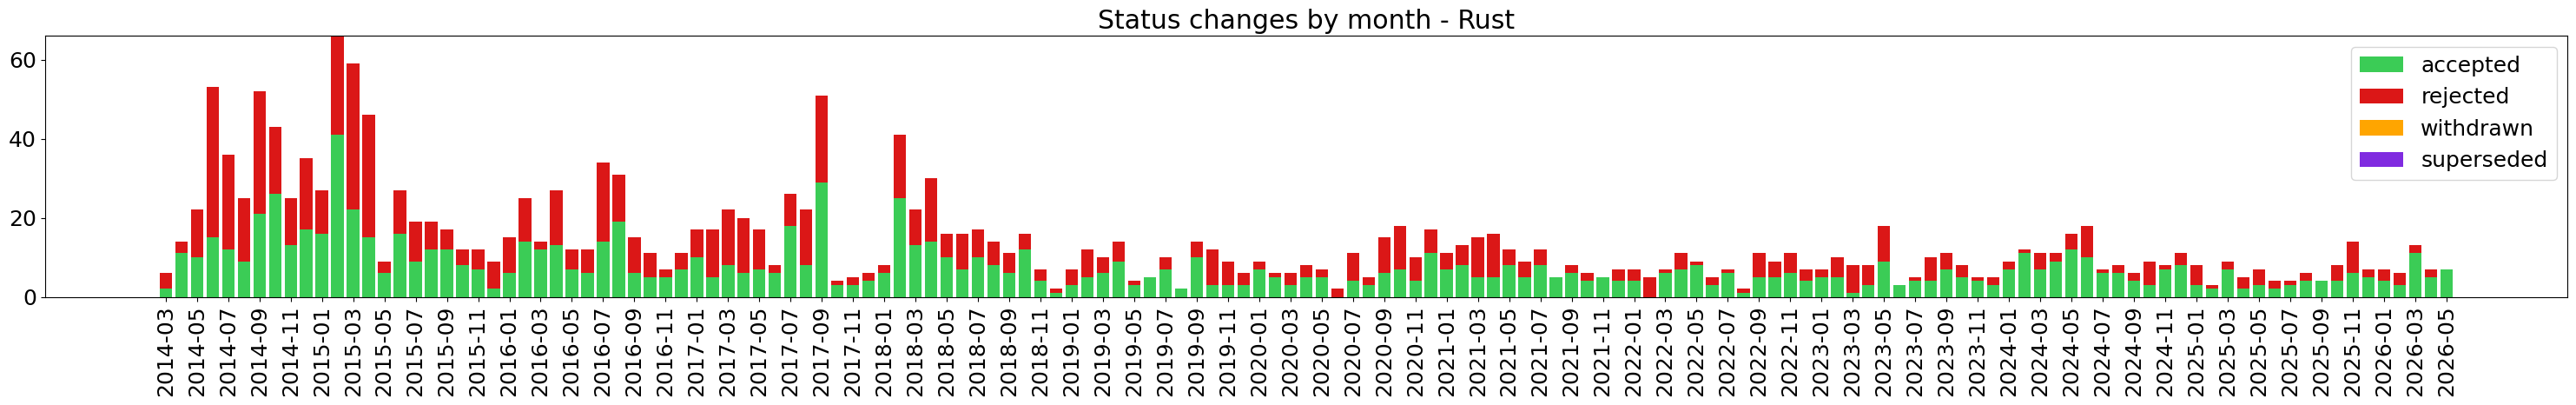

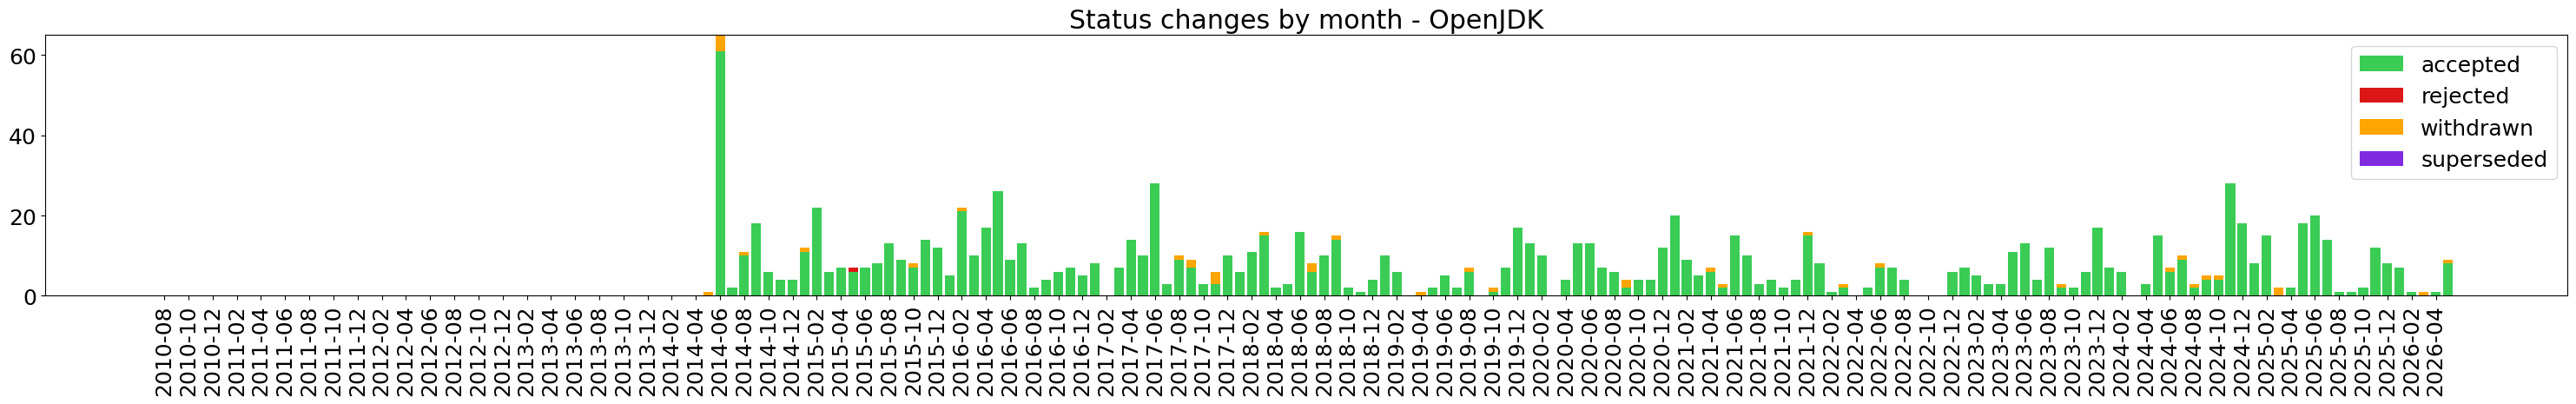

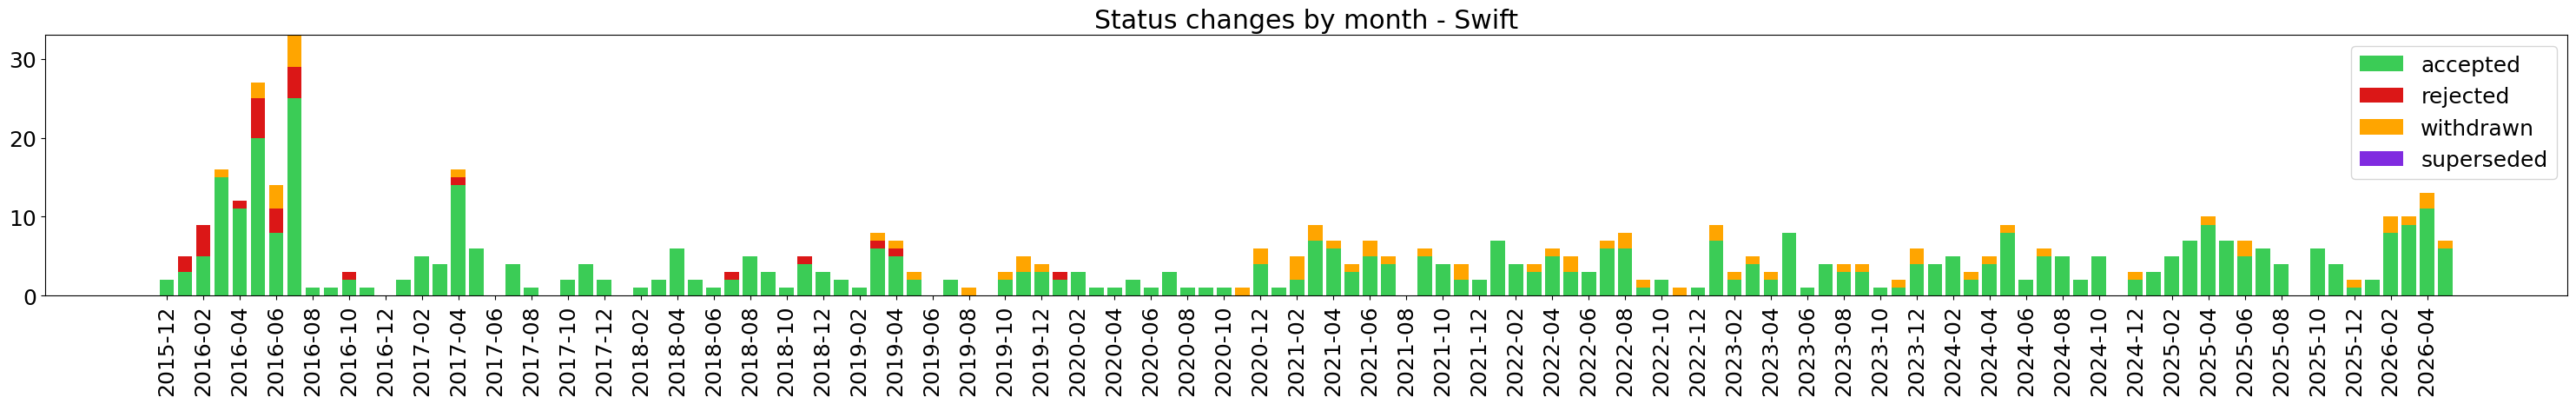

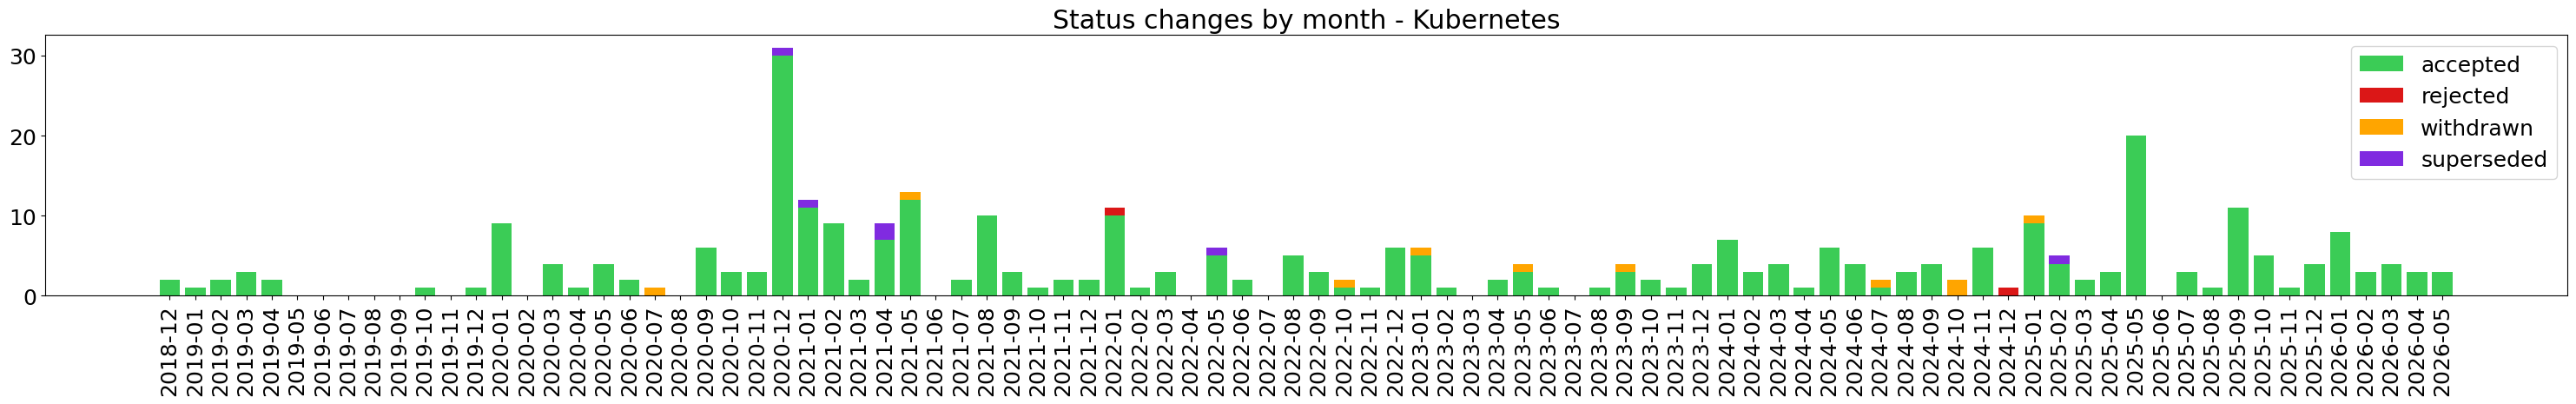

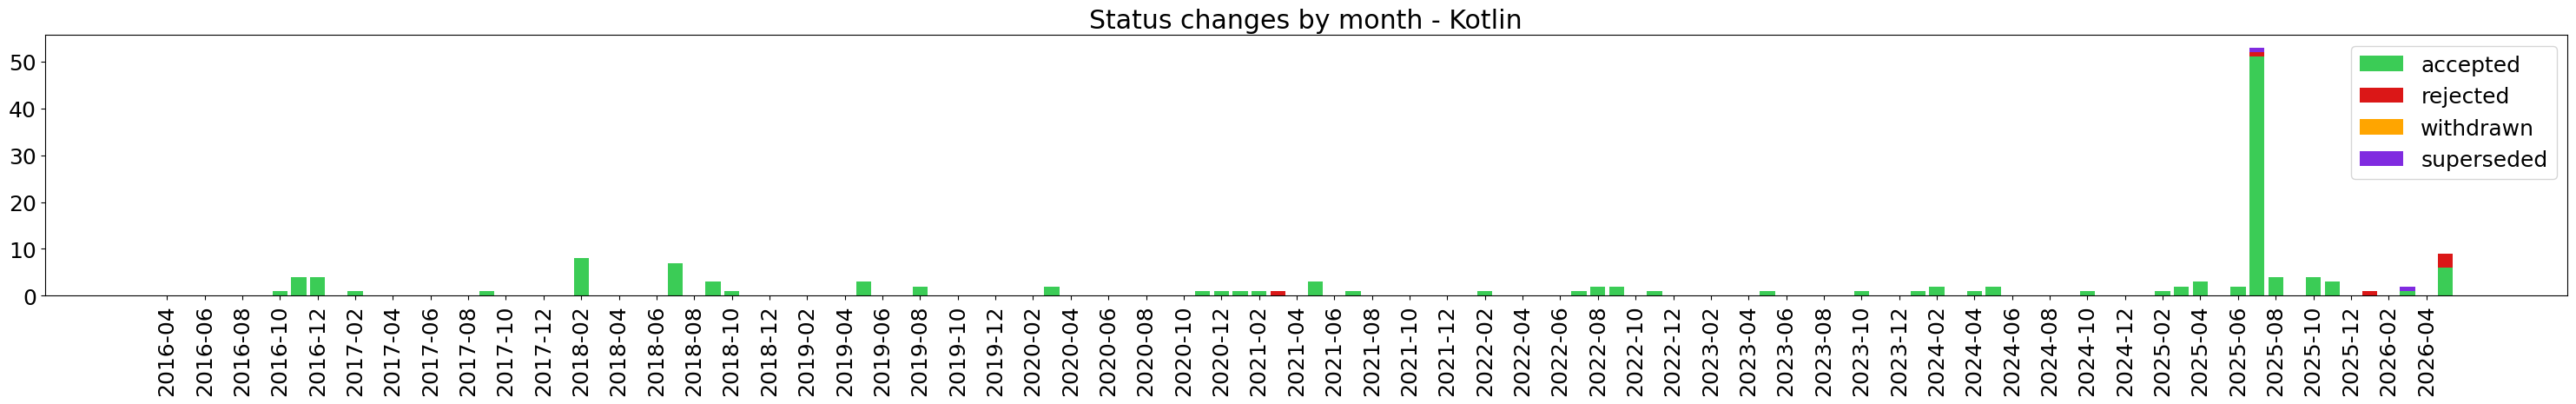

In [102]:
plt.rc('font', size=18)
for proj_id in project_ids_to_explore:
  stat_changes_months = {stat: Counter[tuple[int, int]]() for stat in NormalisedStatus}
  for change_date, new_stat in session.execute(select(ProposalStatus.created_at, ProposalStatus.normalised_status)
      .where(ProposalStatus.project_id.is_(proj_id))):
    stat_changes_months[new_stat][(change_date.year, change_date.month)] += 1

  all_months = {year_month for c in stat_changes_months.values() for year_month in c}
  first_year, first_month = min(all_months)
  last_year, last_month = max(all_months)
  time_line = [(y, m) for y in range(first_year, last_year+1) for m in range(1, 13)
    if (y, m) >= (first_year, first_month) and (y, m) <= (last_year, last_month)]

  cumul_month_counts = Counter[tuple[int, int]]()
  months = [f'{year}-{month:02n}' for year, month in time_line]
  _ = plt.figure(figsize=(30, 5))
  for stat in final_stats:
    _ = plt.bar(months, [stat_changes_months[stat][year_month] for year_month in time_line],
      bottom=[cumul_month_counts[year_month] for year_month in time_line],
      label=stat.value, color=status_color[stat])
    cumul_month_counts += stat_changes_months[stat]
  _ = plt.title(f'Status changes by month - {projects[proj_id].project_name}')
  _ = plt.xticks(months[::len(months) // 120 + 1], rotation=90)
  _ = plt.legend()
  show_and_save(f'time_stats_{projects[proj_id].project_name}')
plt.rcdefaults()

## Acceptance statistics in terms of number of comments

In [80]:
from sqlalchemy import true

def proposal_first_final_mention_of_stat(proj_id: int, prop_id: str, stat: NormalisedStatus) -> datetime | None:
  if stat not in final_stats:
    return None
  res = session.scalar(text("""
    select created_at from
    (select *, lag(normalised_status) over (order by created_at) prev_stat
    from ProposalStatus where project_id == :proj_id and proposal_id == :prop_id)
    where normalised_status == :stat
    and (prev_stat is null or prev_stat != :stat)
    order by created_at desc limit 1"""),
    params={'proj_id': proj_id, 'prop_id': prop_id, 'stat': stat})
  return None if res is None else datetime.fromisoformat(res)

def proposal_comments_until_date(proj_id: int, prop_id: str, date: datetime | None) -> int:
  return session.scalar(select(func.count()).select_from(Comment)
    .where(Comment.project_id.is_(proj_id))
    .where(Comment.proposal_id.is_(prop_id))
    .where(true() if date is None else func.date(Comment.created_at) <= date)) or 0

In [85]:
props_per_project_stat_comms = {proj_id: {stat: Counter[int]() for stat in NormalisedStatus} for proj_id in project_ids_to_explore}
for proj_id in project_ids_to_explore:
  prop_ids = project_proposals(proj_id)
  prop_latest_stats = [(prop_id, proposal_latest_status(proj_id, prop_id)) for prop_id in prop_ids]
  prop_latest_stats = [(prop_id, stat[1]) for prop_id, stat in prop_latest_stats if stat is not None]
  for prop_id, stat in prop_latest_stats:
    verdict_date = proposal_first_final_mention_of_stat(proj_id, prop_id, stat)
    comm_count = proposal_comments_until_date(proj_id, prop_id, verdict_date)
    props_per_project_stat_comms[proj_id][stat][comm_count] += 1

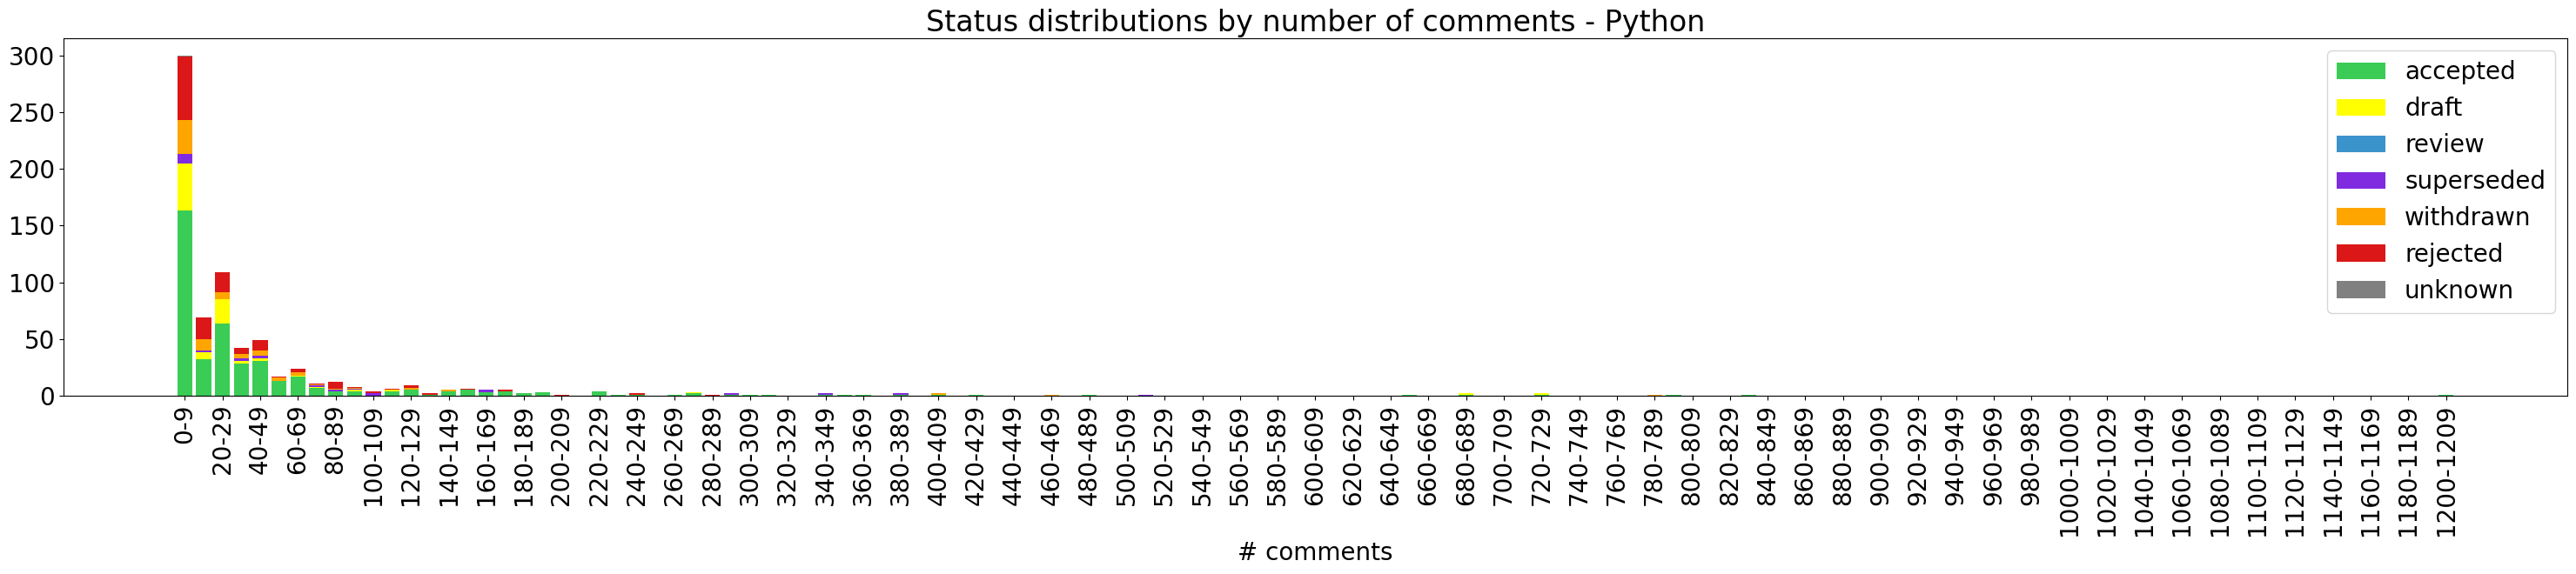

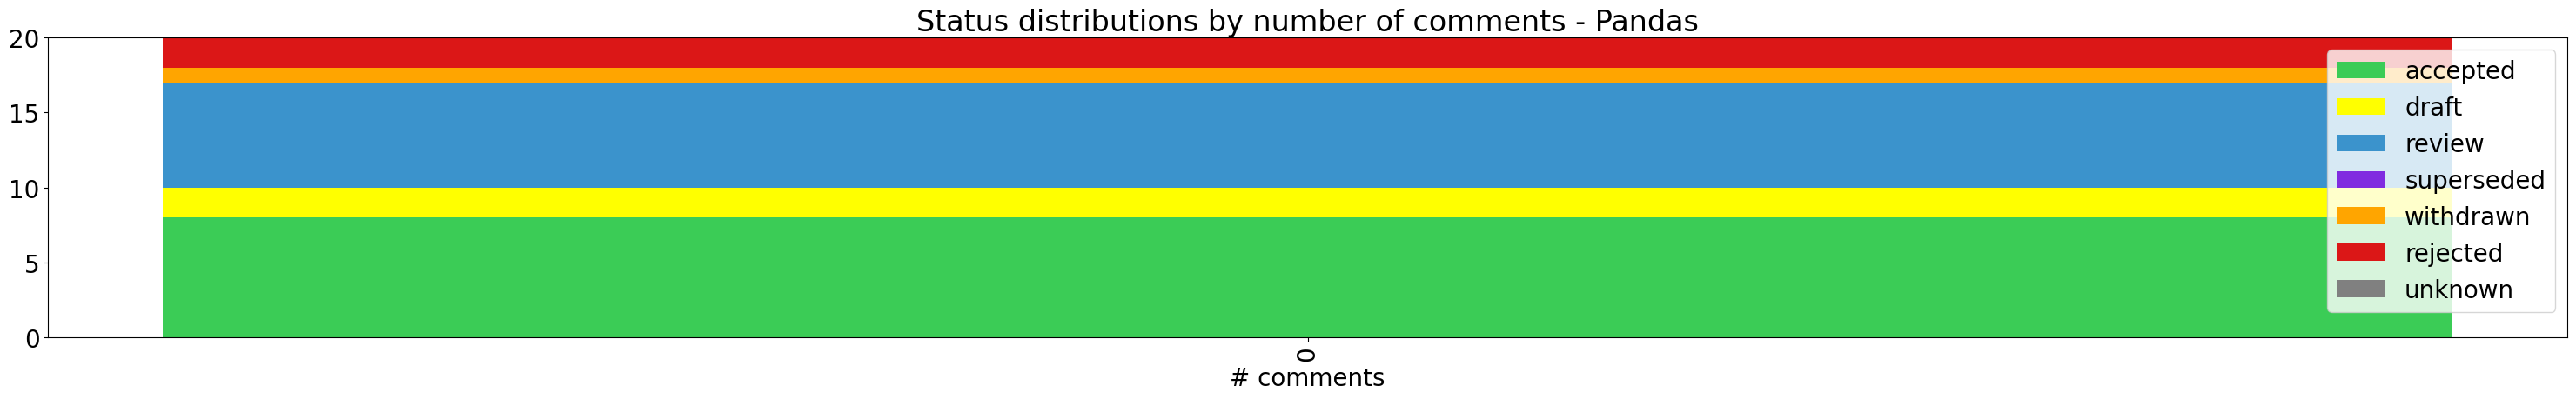

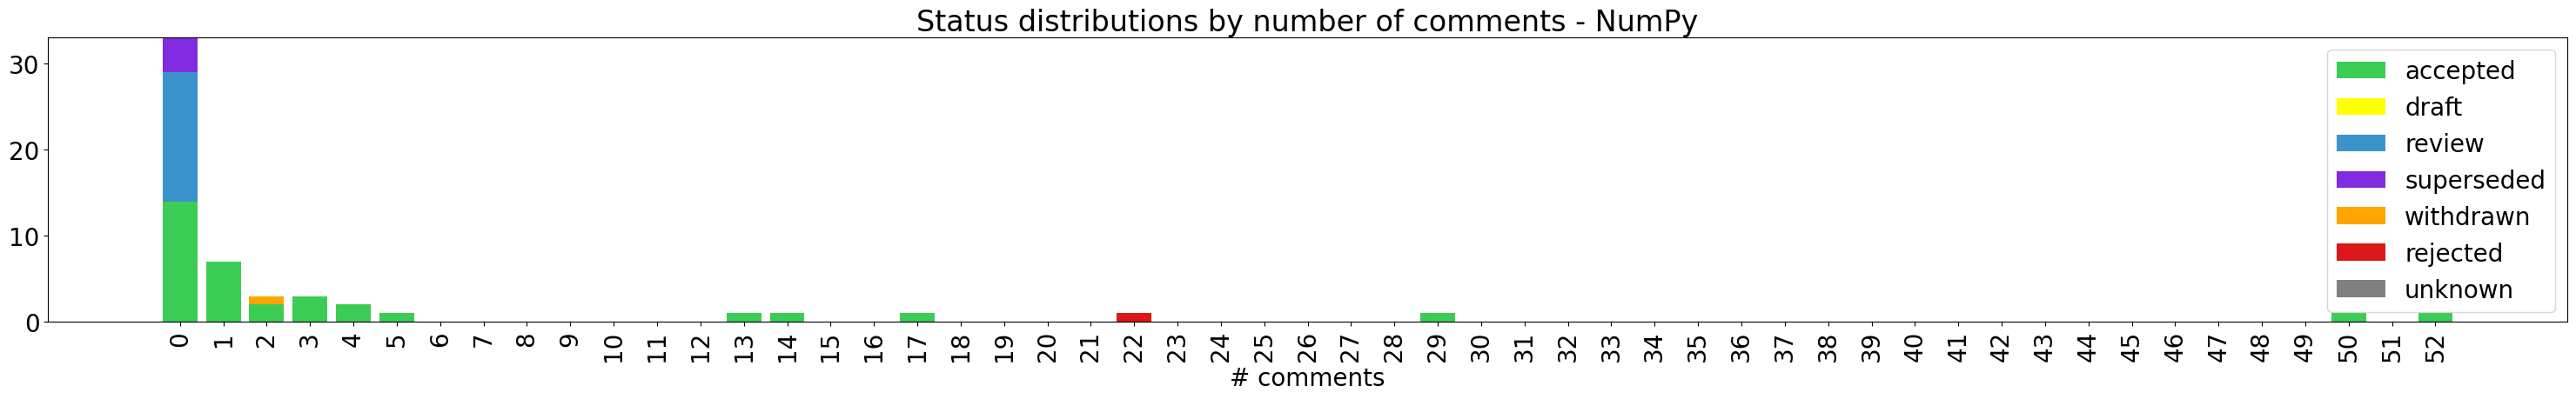

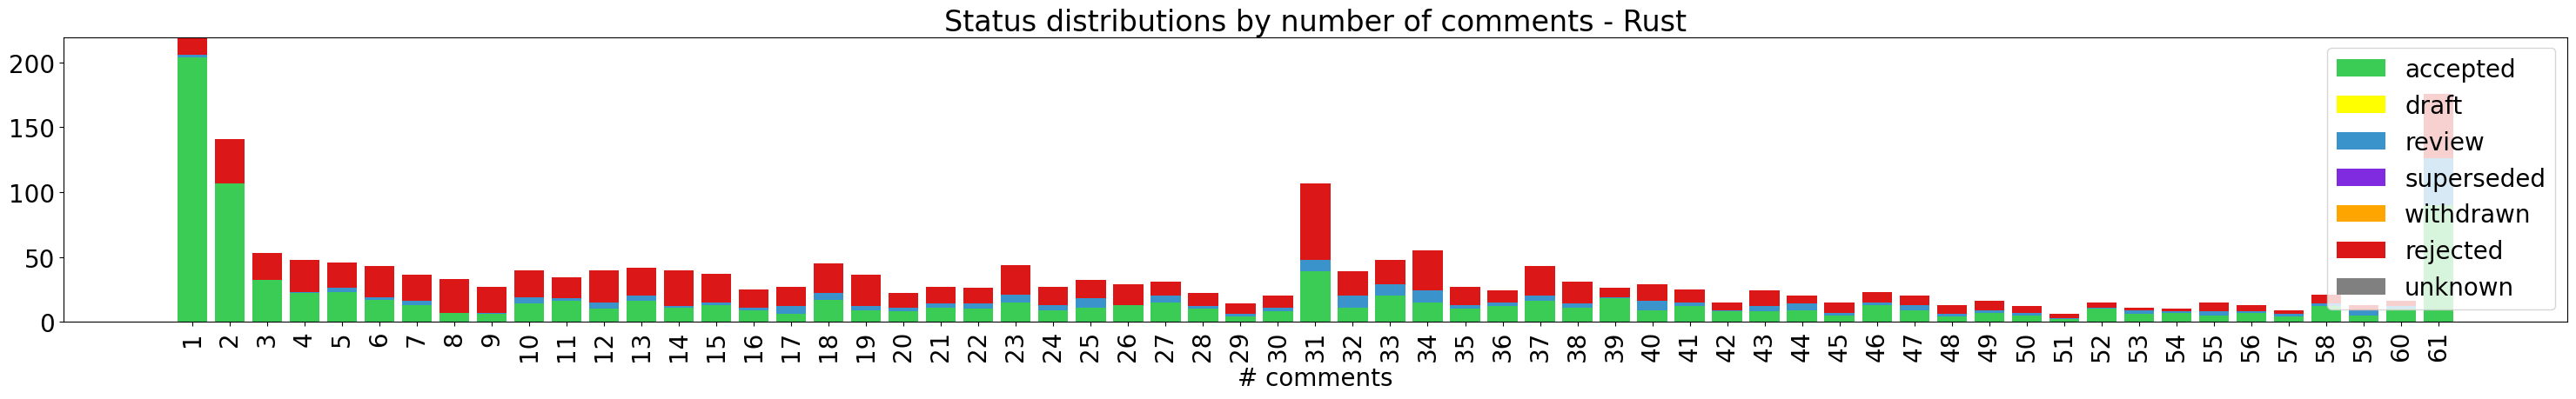

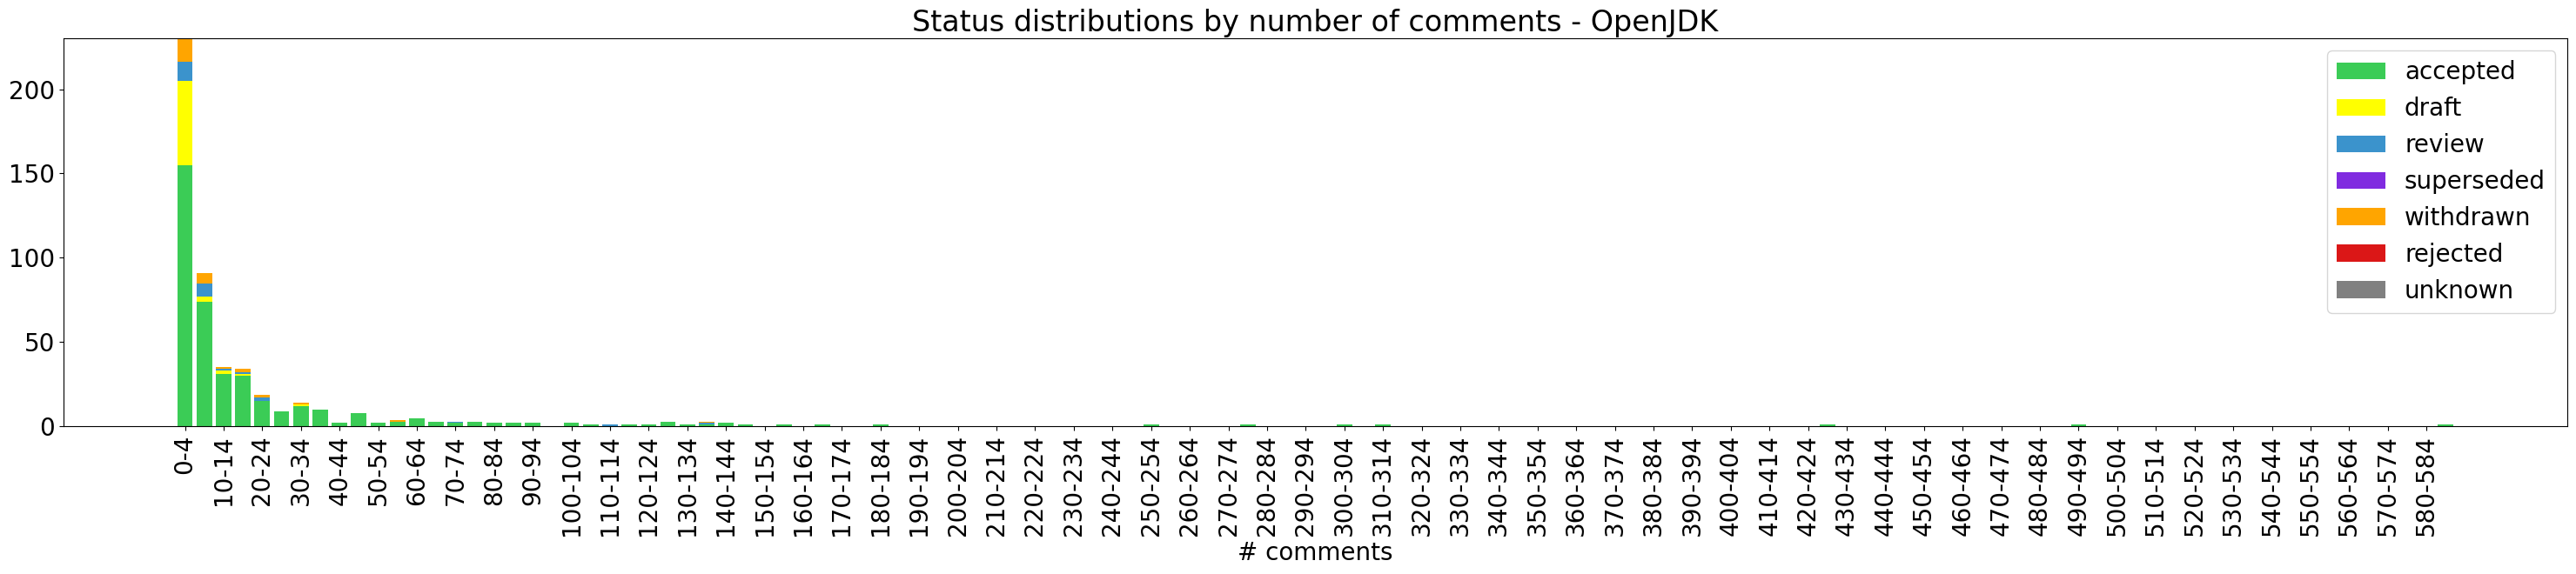

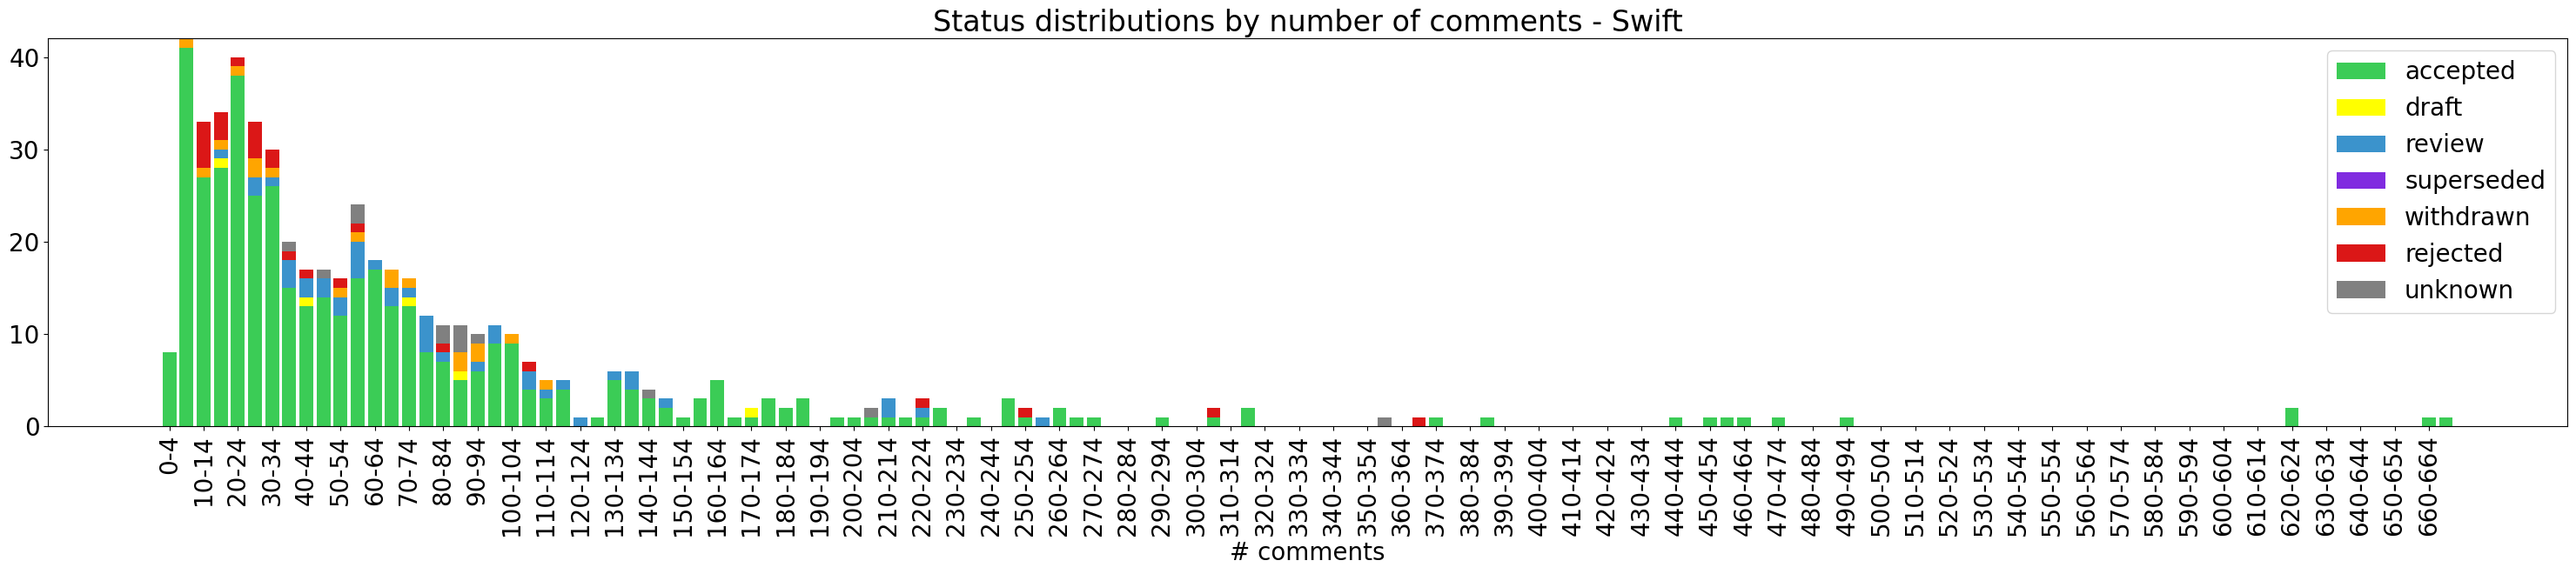

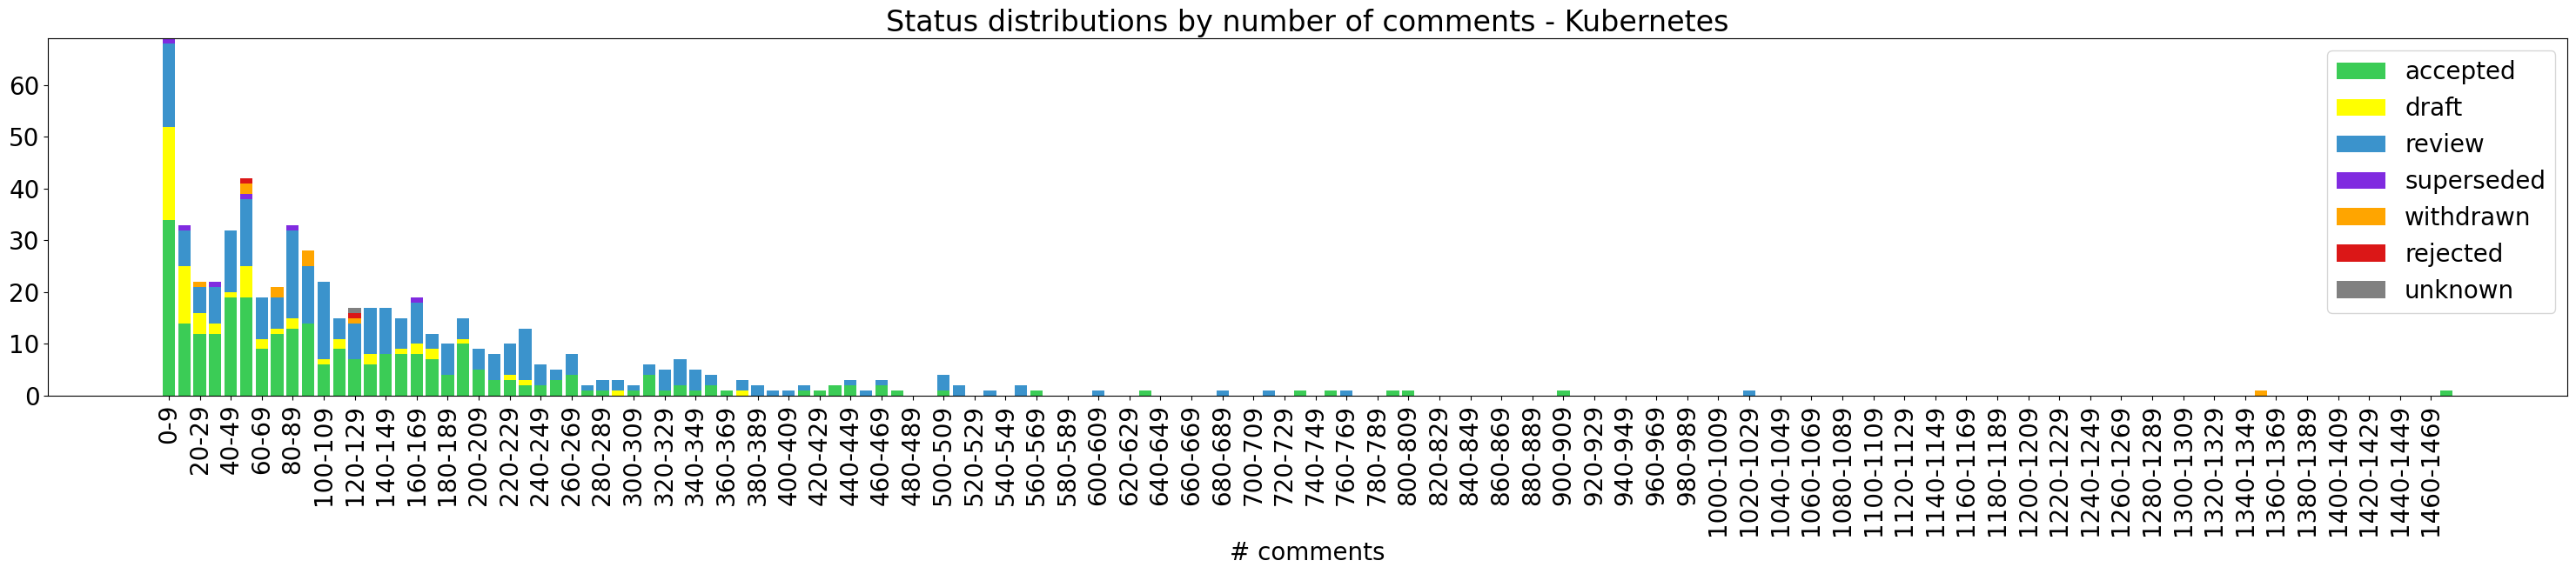

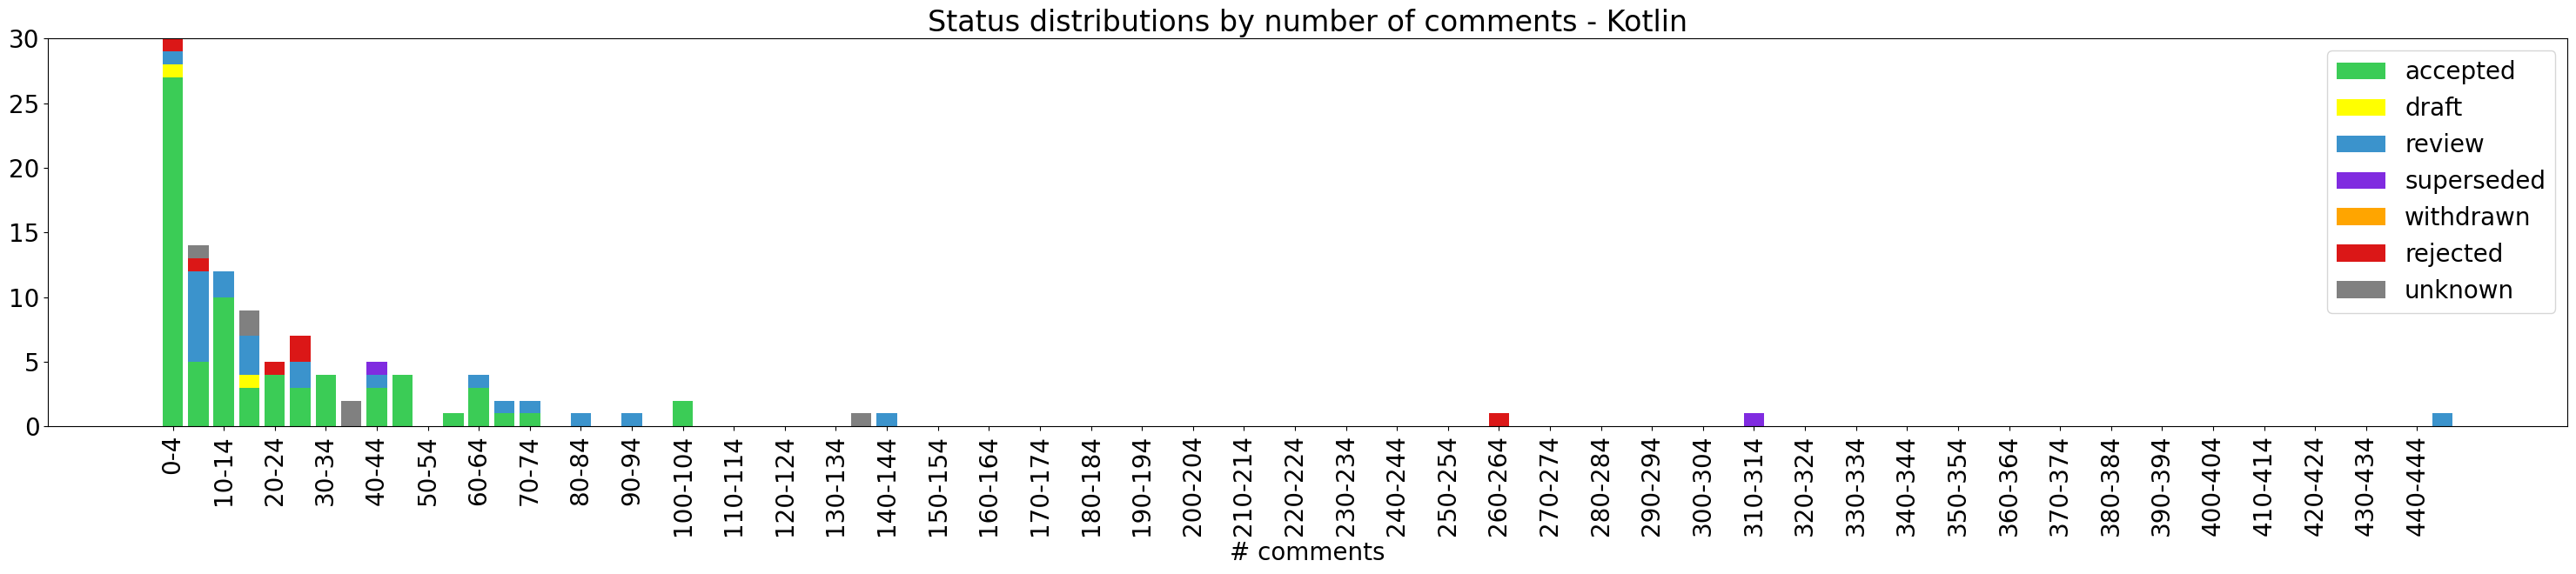

In [91]:
from math import ceil

plt.rc('font', size=20)
for proj_id in project_ids_to_explore:
  props_per_stat_and_comms = props_per_project_stat_comms[proj_id]
  
  all_comm_nums = {comm_num for counts in props_per_stat_and_comms.values() for comm_num in counts}
  comm_nums = list(range(min(all_comm_nums), max(all_comm_nums) + 1))

  cumul_comm_num_counts = Counter[int]()
  if comm_nums[-1] - comm_nums[0] >= 200:
    _ = plt.figure(figsize=(30, 7))
    # group in buckets if there are too many bars
    bucket_width = 10 if comm_nums[-1] - comm_nums[0] >= 1000 else 5
    n_buckets = comm_nums[-1] // bucket_width + 1
    cumul_buckets = np.zeros(n_buckets, dtype=int)
    buckets = [f'{i * bucket_width}-{(i+1) * bucket_width - 1}' for i in range(n_buckets)]
    for stat in NormalisedStatus:
      stat_buckets = np.zeros(n_buckets, dtype=int)
      for comms, cnt in props_per_stat_and_comms[stat].items():
        stat_buckets[comms // bucket_width] += cnt
      _ = plt.bar(buckets, stat_buckets, bottom=cumul_buckets,
        label=stat.value, color = status_color[stat])
      cumul_buckets += stat_buckets
    _ = plt.xticks(buckets[::2], rotation=90)
  else:
    _ = plt.figure(figsize=(30, 5))
    for stat in NormalisedStatus:
      _ = plt.bar(comm_nums, [props_per_stat_and_comms[stat][comm_num] for comm_num in comm_nums],
        bottom=[cumul_comm_num_counts[comm_num] for comm_num in comm_nums],
        label=stat.value, color=status_color[stat])
      cumul_comm_num_counts += props_per_stat_and_comms[stat]
    _ = plt.xticks(comm_nums[::ceil(len(comm_nums) / 100)], rotation=90)
  _ = plt.title(f'Status distributions by number of comments - {projects[proj_id].project_name}')
  _ = plt.xlabel('# comments')
  _ = plt.legend()
  show_and_save(f'comm_num_stats_{projects[proj_id].project_name}')
plt.rcdefaults()